# 00 — Validation: reproduce published MAE

Before any analysis we confirm we can reproduce the MAE numbers from Table 3 of Lago et al. (2021).  
If our number matches the published value, we trust the data loading. If not, we stop and find out why.

**Published target (NP, DNN Ensemble MAE): 1.667**

> **Revision of 14 Oct 2026** (feedback of 13 Oct 2026). This is the exploratory log; the reference analysis is `cross_market_decision.ipynb`. Changes: (1) the predictive distribution uses residuals p − p̂, as in thesis eq. 3.5 (the earlier code used p̂ − p, which mirrored the distribution and moved price spikes into the lower tail); (2) the DM test is run on daily means, two-sided, and is applied to MSE, MAE and regret; (3) gap-factor ratios are removed; (4) tail bias and calibration are grouped by forecast decile, to avoid the selection effect of grouping by realised price; (5) the regret and DM helpers come from `decision_utils.py`. Interpretation cells were rewritten from the new outputs; where an earlier interpretation is kept for the record, it carries a correction note.

## Why validation comes first

The central research question of this thesis is:

> **As a buyer becomes more risk-averse, does the model that is most accurate by standard metrics also produce the best decisions — or do accuracy rankings and decision rankings diverge?**

To answer that, we rely entirely on the published forecast files from Lago et al. (2021). We did not train these models ourselves. That means before we trust a single number downstream, we need to confirm that:
1. We are reading the files correctly
2. The numbers we compute match what the paper reports

If our MAE does not match the published MAE, something is wrong with our data loading — and every downstream analysis would be built on a broken foundation. This cell reproduces the simplest published number (MAE) as a sanity check.

---

## What are DNN and LEAR?

These are the two families of forecasting models in the benchmark. Both produce **point forecasts** — a single predicted price for each hour. They differ fundamentally in how they are built.

### LEAR — Lasso Estimated AutoRegressive model
A linear regression model that predicts tomorrow's hourly prices using:
- Recent past prices (lags)
- Calendar features (hour, day of week, month)
- Exogenous inputs (load forecast, generation forecast)

The "Lasso" part adds a penalty that shrinks irrelevant coefficients to zero, performing automatic variable selection. Because it is a deterministic mathematical procedure — given the same data, solve the same equation — it always produces **identical forecasts**. The number in the CSV is the only number it could ever produce.

The suffix in the column name (56, 84, 1092, 1456) is the **training window in days** — how many days of history the model used.

### DNN — Deep Neural Network
A multi-layer neural network trained to minimise squared forecast error. It uses the same inputs as LEAR but can learn non-linear relationships. The catch: training involves **random initialisation** of weights and **stochastic gradient descent** — both sources of randomness. Two training runs on identical data will produce slightly different models and therefore slightly different forecasts.

The paper trained four DNN variants and averaged them into a `DNN Ensemble`. But the specific run that produced the CSV file may differ from the run the authors used when computing the table in the paper. That is the expected and benign reason why DNN MAE will not reproduce exactly.

### Why this asymmetry matters for our research
LEAR is a well-understood linear model. DNN is a black box with stochastic training. If we eventually find that one model is better for risk-averse decisions, we need to understand *why* — and the interpretability of LEAR vs. DNN is part of that story.

In [1]:
# Paths and shared helpers (decision_utils.py lives next to this notebook)
import numpy as np
import pandas as pd
from decision_utils import DATA_DIR, FIG_DIR

FIG_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
import pandas as pd

# Load the NP forecast file
# index_col=0 treats the unnamed datetime column as the index
# parse_dates=True converts it from string to DatetimeIndex
df = pd.read_csv(
    f"{DATA_DIR}/Forecasts_NP_DNN_LEAR_ensembles.csv",
    index_col=0,
    parse_dates=True,
)

# Confirm what we have before computing anything
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("Date range:", df.index[0], "→", df.index[-1])
print("Any nulls:", df.isnull().sum().sum())
df.head(3)

Shape: (17472, 11)
Columns: ['Real price', 'DNN 1', 'DNN 2', 'DNN 3', 'DNN 4', 'DNN Ensemble', 'LEAR 56', 'LEAR 84', 'LEAR 1092', 'LEAR 1456', 'LEAR Ensemble']
Date range: 2016-12-27 00:00:00 → 2018-12-24 23:00:00
Any nulls: 0


,Real price,DNN 1,DNN 2,DNN 3,DNN 4,DNN Ensemble,LEAR 56,LEAR 84,LEAR 1092,LEAR 1456,LEAR Ensemble
2016-12-27 00:00:00,24.08,24.530144,24.838255,25.126823,25.108997,24.901055,25.1290,24.9381,24.3565,24.8109,24.808625
2016-12-27 01:00:00,22.52,23.115845,23.608419,23.390991,23.871862,23.496779,24.2083,24.4645,22.0323,22.6447,23.337450
2016-12-27 02:00:00,20.13,22.563509,22.815233,22.686951,23.168064,22.808439,23.9289,23.8766,20.9948,20.8664,22.416675


## Step 1 — Load the data and inspect it

We start with Nord Pool (NP) as a representative market. Before computing anything, we confirm the file loads correctly:
- **Shape** should be (17472, 11) — 17,472 hourly observations, 11 columns
- **Date range** should span the out-of-sample test period (roughly two years)
- **Nulls** should be zero — any missing value would corrupt our metrics silently

`index_col=0` tells pandas the first column is the row index (the datetime).  
`parse_dates=True` converts those strings into a proper `DatetimeIndex` so we can do time-based operations later.

In [3]:
mae_dnn = (df["DNN Ensemble"] - df["Real price"]).abs().mean()
mae_lear = (df["LEAR Ensemble"] - df["Real price"]).abs().mean()

print(f"DNN Ensemble MAE:  {mae_dnn:.3f}  (published: 1.667)")
print(f"LEAR Ensemble MAE: {mae_lear:.3f}  (published: 1.738)")

DNN Ensemble MAE:  1.683  (published: 1.667)
LEAR Ensemble MAE: 1.738  (published: 1.738)


## Step 2 — Compute MAE for NP

**MAE (Mean Absolute Error)** is the average of the absolute differences between forecast and realised price:

$$\text{MAE} = \frac{1}{T} \sum_{t=1}^{T} |\hat{p}_t - p_t|$$

where $\hat{p}_t$ is the forecast and $p_t$ is the realised price.

It treats over-forecasts and under-forecasts symmetrically, and is expressed in the same units as the price (EUR/MWh). A lower MAE means a more accurate forecast on average.

**Why MAE and not RMSE?** MAE is less sensitive to large individual errors than RMSE (which squares the differences). In electricity markets with occasional price spikes, RMSE can be dominated by a handful of extreme hours. MAE gives a more stable picture of typical accuracy — which is exactly why Lago et al. use it as their primary metric.

**The connection to our research question:** MAE weights every hour equally. It does not care whether the error occurs during a cheap hour or an expensive hour. A risk-averse buyer, however, cares *a lot* about expensive hours — getting those wrong costs more. That mismatch between what MAE measures and what the buyer needs is the central tension this thesis explores.

## All five markets

LEAR is deterministic — same data, same model, same output every time. So its MAE should reproduce exactly.  
DNN uses random initialisation and stochastic gradient descent. The CSV contains one particular training run; the paper may have reported a different run. A small gap is expected and is **not** a data loading error.

We now loop over all five markets to confirm this pattern holds.

### The five markets

| Code | Market | Currency | Notes |
|---|---|---|---|
| **NP** | Nord Pool (Scandinavia) | EUR/MWh | Hydro-dominated; prices generally low and stable |
| **PJM** | PJM Interconnection (US mid-Atlantic) | $/MWh | Large thermal system; different price dynamics to Europe |
| **BE** | Belgium | EUR/MWh | Small, highly interconnected with FR and DE |
| **FR** | France | EUR/MWh | Nuclear-heavy; distinct seasonal pattern |
| **DE** | Germany | EUR/MWh | Large renewables share; frequent near-zero and negative prices |

Price levels differ substantially across markets — that is why the paper uses **rMAE** (relative MAE, normalised by a naive forecast) as its headline metric rather than raw MAE. We will tackle rMAE after confirming the raw MAE first.

In [4]:
import pandas as pd

# Published MAE values from Lago et al. (2021), Table 3
published = {
    "NP":  {"DNN": 1.667, "LEAR": 1.738},
    "PJM": {"DNN": 2.779, "LEAR": 3.013},
    "BE":  {"DNN": 5.821, "LEAR": 6.140},
    "FR":  {"DNN": 3.910, "LEAR": 3.980},
    "DE":  {"DNN": 3.441, "LEAR": 3.609},
}

rows = []
for market, targets in published.items():
    path = f"{DATA_DIR}/Forecasts_{market}_DNN_LEAR_ensembles.csv"
    d = pd.read_csv(path, index_col=0, parse_dates=True)
    mae_dnn  = (d["DNN Ensemble"]  - d["Real price"]).abs().mean()
    mae_lear = (d["LEAR Ensemble"] - d["Real price"]).abs().mean()
    rows.append({
        "Market":       market,
        "DNN (ours)":   round(mae_dnn,  3),
        "DNN (paper)":  targets["DNN"],
        "DNN diff":     round(mae_dnn  - targets["DNN"], 3),
        "LEAR (ours)":  round(mae_lear, 3),
        "LEAR (paper)": targets["LEAR"],
        "LEAR diff":    round(mae_lear - targets["LEAR"], 3),
    })

results = pd.DataFrame(rows).set_index("Market")
results

,DNN (ours),DNN (paper),DNN diff,LEAR (ours),LEAR (paper),LEAR diff
Market,,,,,,
NP,1.683,1.667,0.016,1.738,1.738,-0.0
PJM,2.862,2.779,0.083,3.013,3.013,0.0
BE,5.870,5.821,0.049,6.140,6.140,0.0
FR,3.866,3.910,-0.044,3.980,3.980,-0.0
DE,3.413,3.441,-0.028,3.609,3.609,0.0


## rMAE — relative Mean Absolute Error

Raw MAE is hard to compare across markets because price levels differ. Nord Pool prices average around 30 EUR/MWh; Belgium around 50 EUR/MWh. A model with MAE = 3 looks better on NP than BE, but that may just reflect the scale of prices, not a genuine difference in forecast quality.

**rMAE normalises this away:**

$$\text{rMAE} = \frac{\text{MAE}_{\text{model}}}{\text{MAE}_{\text{naive}}}$$

A value below 1 means the model beats the naive benchmark. A value of 0.42 (LEAR on NP) means the model's error is 42% of what a naive forecast would make — the model captures 58% of what was forecastable.

### What is the naive forecast?

The naive forecast uses no model and no learning — just a single rule:

- **1-day lag**: forecast = price at the same hour yesterday
- **7-day lag**: forecast = price at the same hour exactly one week ago

Both are valid conventions. The paper does not state which one it uses. We reverse-engineer it:  
since LEAR reproduces exactly, the implied naive MAE must be `1.738 / 0.420 ≈ 4.138`.  
We try both conventions and see which one hits that target.

In [5]:
# Target naive MAE implied by the published LEAR rMAE (which reproduced exactly)
target_naive_mae = 1.738 / 0.420
print(f"Target naive MAE: {target_naive_mae:.4f}")

# 1-day lag naive: forecast for hour t = actual price at hour t-24
naive_1d = df["Real price"].shift(24)

# 7-day lag naive: forecast for hour t = actual price at hour t-168 (24*7)
naive_7d = df["Real price"].shift(168)

# Compute MAE for each (dropna removes the burn-in period at the start)
mae_naive_1d = (naive_1d - df["Real price"]).abs().dropna().mean()
mae_naive_7d = (naive_7d - df["Real price"]).abs().dropna().mean()

print(f"\n1-day lag naive MAE:  {mae_naive_1d:.4f}")
print(f"7-day lag naive MAE:  {mae_naive_7d:.4f}")
print(f"Target:               {target_naive_mae:.4f}")

Target naive MAE: 4.1381

1-day lag naive MAE:  2.8864
7-day lag naive MAE:  4.1347
Target:               4.1381


## rMAE across all five markets

Now that we have confirmed the naive benchmark (7-day same-hour lag), we compute rMAE for both ensembles across all five markets and compare to the published table.

One subtlety: the 7-day lag requires the first 168 hours (7 × 24) to be dropped — there is no "same hour last week" for the opening week of the test period. We apply `.dropna()` consistently to both the naive and model errors so the denominator and numerator are computed over the same rows.

In [6]:
published = {
    "NP":  {"DNN": 0.403, "LEAR": 0.420},
    "PJM": {"DNN": 0.439, "LEAR": 0.476},
    "BE":  {"DNN": 0.573, "LEAR": 0.604},
    "FR":  {"DNN": 0.533, "LEAR": 0.543},
    "DE":  {"DNN": 0.377, "LEAR": 0.395},
}

rows = []
for market, targets in published.items():
    path = f"{DATA_DIR}/Forecasts_{market}_DNN_LEAR_ensembles.csv"
    d = pd.read_csv(path, index_col=0, parse_dates=True)

    # 7-day naive forecast: same hour, one week ago
    naive = d["Real price"].shift(168)

    # Align all series to the same non-null rows
    mask = naive.notna()
    mae_naive = (naive[mask] - d["Real price"][mask]).abs().mean()
    mae_dnn   = (d["DNN Ensemble"][mask]  - d["Real price"][mask]).abs().mean()
    mae_lear  = (d["LEAR Ensemble"][mask] - d["Real price"][mask]).abs().mean()

    rmae_dnn  = mae_dnn  / mae_naive
    rmae_lear = mae_lear / mae_naive

    rows.append({
        "Market":        market,
        "DNN rMAE":      round(rmae_dnn,  3),
        "DNN (paper)":   targets["DNN"],
        "DNN diff":      round(rmae_dnn  - targets["DNN"], 3),
        "LEAR rMAE":     round(rmae_lear, 3),
        "LEAR (paper)":  targets["LEAR"],
        "LEAR diff":     round(rmae_lear - targets["LEAR"], 3),
    })

pd.DataFrame(rows).set_index("Market")

,DNN rMAE,DNN (paper),DNN diff,LEAR rMAE,LEAR (paper),LEAR diff
Market,,,,,,
NP,0.408,0.403,0.005,0.422,0.420,0.002
PJM,0.455,0.439,0.016,0.478,0.476,0.002
BE,0.580,0.573,0.007,0.607,0.604,0.003
FR,0.528,0.533,-0.005,0.544,0.543,0.001
DE,0.374,0.377,-0.003,0.396,0.395,0.001


---

# Phase 1 — Exploratory Data Analysis

Before analysing forecast errors or making decisions, we need to understand the raw price data itself. Problems here — gaps, anomalies, unusual distributions — will silently corrupt everything downstream.

We work through four questions in order:
1. **Data quality**: is the hourly grid complete? Any gaps, duplicates, or DST anomalies?
2. **Price distributions**: what do prices look like — level, spread, skew, negative values?
3. **Seasonal structure**: how do prices vary by hour, day of week, and month?
4. **Cross-market dependence**: are the five markets independent evidence, or correlated?

## Step 1 — Data quality: is the hourly grid complete?

An hourly dataset covering 2 years should have exactly 17,520 hours (365 × 2 × 24). We have 17,472 — already 48 hours short, which is worth understanding.

We check three things:
- **Expected vs actual row count** given the date range
- **Gaps**: missing hours in the sequence
- **Duplicates**: the same timestamp appearing twice (can happen at DST fall-back)

We start with NP, then loop over all markets.

In [7]:
df_np = pd.read_csv(
    f"{DATA_DIR}/Forecasts_NP_DNN_LEAR_ensembles.csv",
    index_col=0, parse_dates=True
)

# Build the complete hourly grid from first to last timestamp
full_grid = pd.date_range(start=df_np.index[0], end=df_np.index[-1], freq="h")

# What is in the grid but not in the data? → gaps
gaps = full_grid.difference(df_np.index)

# What is in the data more than once? → duplicates
duplicates = df_np.index[df_np.index.duplicated()]

print(f"Date range:       {df_np.index[0]}  →  {df_np.index[-1]}")
print(f"Expected hours:   {len(full_grid)}")
print(f"Actual rows:      {len(df_np)}")
print(f"Missing hours:    {len(gaps)}")
print(f"Duplicate timestamps: {len(duplicates)}")

if len(gaps) > 0:
    print(f"\nFirst few gaps:\n{gaps[:10]}")

Date range:       2016-12-27 00:00:00  →  2018-12-24 23:00:00
Expected hours:   17472
Actual rows:      17472
Missing hours:    0
Duplicate timestamps: 0


## Data quality — all five markets

We repeat the grid check for all markets and add two more checks:
- **Negative prices**: occur when excess renewable generation forces prices below zero. Common in Germany. Relevant to our research because CVaR on a distribution with negative values behaves differently.
- **Date ranges**: the test windows differ by market — important before any cross-market comparison.

In [8]:
markets = ["NP", "PJM", "BE", "FR", "DE"]
rows = []

for market in markets:
    path = f"{DATA_DIR}/Forecasts_{market}_DNN_LEAR_ensembles.csv"
    d = pd.read_csv(path, index_col=0, parse_dates=True)
    prices = d["Real price"]

    full_grid = pd.date_range(start=d.index[0], end=d.index[-1], freq="h")
    gaps = len(full_grid.difference(d.index))
    dupes = d.index.duplicated().sum()

    rows.append({
        "Market":       market,
        "Start":        str(d.index[0].date()),
        "End":          str(d.index[-1].date()),
        "Rows":         len(d),
        "Gaps":         gaps,
        "Duplicates":   dupes,
        "Negative prices": (prices < 0).sum(),
        "% negative":   round(100 * (prices < 0).mean(), 2),
    })

pd.DataFrame(rows).set_index("Market")

,Start,End,Rows,Gaps,Duplicates,Negative prices,% negative
Market,,,,,,,
NP,2016-12-27,2018-12-24,17472,0,0,0,0.00
PJM,2016-12-27,2018-12-24,17472,0,0,74,0.42
BE,2015-01-04,2016-12-31,17472,0,0,2,0.01
FR,2015-01-04,2016-12-31,17472,0,0,2,0.01
DE,2016-01-04,2017-12-31,17472,0,0,241,1.38


### Key finding: non-overlapping test windows

The five markets do **not** share the same test period:

| Markets | Period |
|---|---|
| BE, FR | 2015–2016 |
| DE | 2016–2017 |
| NP, PJM | 2016–2018 |

**Implication for the thesis:** Any difference observed across markets conflates two things — the market's structural characteristics and the time period it was evaluated on. We cannot fully separate them. This means claims like "confirmed on five independent markets" overstate the evidence. The five markets are better described as five experiments with different designs, not five replications of the same experiment.

For cross-market comparisons of tail risk and CVaR in particular, this is a serious limitation: we are comparing different calendar years, which may have had very different volatility regimes.

**What to do:** Analyse each market on its own terms first. Be cautious about pooling or ranking across markets. Flag this limitation explicitly in the thesis.

## Step 2 — Price distributions

We now look at what prices actually look like across the five markets. Four summary statistics matter here:

- **Mean**: the average price level
- **Standard deviation**: how much prices vary around that mean
- **Skewness**: direction of the long tail. Electricity prices are typically **right-skewed** — most hours are near the mean, but occasional demand spikes or outages push prices far to the right. Negative prices create a small left bump but rarely dominate the right tail.
- **Kurtosis**: how heavy the tails are compared to a normal distribution. High kurtosis means extreme events are more common than a normal distribution would predict — important for CVaR calculations.

We also plot a histogram for each market so the shape is visible, not just summarised.

      Mean    Std     Min     Max  Skewness  Kurtosis
NP   36.51  10.72    2.17  198.29      0.90      3.78
PJM  27.83  11.21   -3.62  184.48      2.08     13.54
BE   40.64  22.91   -5.00  696.02      8.01    147.22
FR   37.59  19.62  -10.69  874.01     13.68    522.89
DE   31.64  15.49 -130.09  163.52      0.08     10.75


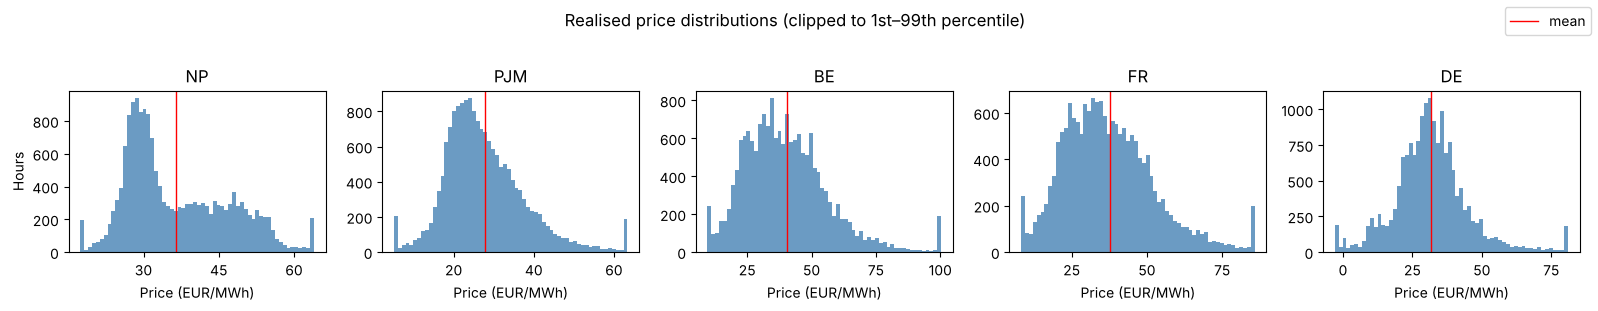

In [9]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

markets = ["NP", "PJM", "BE", "FR", "DE"]
data = {}
for market in markets:
    path = f"{DATA_DIR}/Forecasts_{market}_DNN_LEAR_ensembles.csv"
    data[market] = pd.read_csv(path, index_col=0, parse_dates=True)["Real price"]

# Summary statistics table
stats = pd.DataFrame({
    m: {
        "Mean":     round(s.mean(), 2),
        "Std":      round(s.std(), 2),
        "Min":      round(s.min(), 2),
        "Max":      round(s.max(), 2),
        "Skewness": round(s.skew(), 2),
        "Kurtosis": round(s.kurtosis(), 2),  # excess kurtosis (normal = 0)
    }
    for m, s in data.items()
}).T

print(stats.to_string())

# Histograms — one per market, clipped at 1st–99th percentile for readability
fig, axes = plt.subplots(1, 5, figsize=(16, 3), sharey=False)
for ax, market in zip(axes, markets):
    s = data[market]
    lo, hi = s.quantile(0.01), s.quantile(0.99)
    ax.hist(s.clip(lo, hi), bins=60, color="steelblue", edgecolor="none", alpha=0.8)
    ax.axvline(s.mean(), color="red", linewidth=1, label="mean")
    ax.set_title(market)
    ax.set_xlabel("Price (EUR/MWh)")
    ax.xaxis.set_major_locator(mticker.MaxNLocator(4))

axes[0].set_ylabel("Hours")
fig.suptitle("Realised price distributions (clipped to 1st–99th percentile)", y=1.02)
fig.legend(["mean"], loc="upper right")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/price_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

### Key findings from price distributions

**Skewness:** All markets are right-skewed — as expected from price spikes — except DE which is near zero (0.08). DE's extreme negative prices (min −130 EUR/MWh, from renewable oversupply) pull the left tail while spikes pull the right, roughly cancelling out. FR (13.68) and BE (8.01) have extreme right skew driven by nuclear outage events (max 874 and 696 EUR/MWh respectively).

**Kurtosis:** All markets have very fat tails (excess kurtosis well above 0). FR at 522 and BE at 147 are extraordinary — a handful of spike hours dominate the tail entirely. This means a normal distribution would badly underestimate the probability of extreme prices.

**Implication for CVaR:** The tail structure differs dramatically across markets:
- In FR and BE: tail risk is concentrated in rare, very large upward spikes → a risk-averse buyer is primarily exposed to nuclear outage events
- In DE: tail risk is two-sided — both upward spikes and extreme negative prices matter
- In NP and PJM: tails are fat but more moderate

This means a single λ (risk aversion parameter) will interact very differently with each market's distribution. Results will not be directly comparable across markets — another reason to analyse each market on its own terms.

## Step 3 — Seasonal structure

Electricity prices follow strong and predictable cycles:
- **Hour of day**: demand peaks during working hours (roughly 8am–8pm) → prices peak then too
- **Day of week**: weekdays have higher industrial and commercial demand than weekends
- **Month**: heating and cooling demand creates seasonal patterns

Understanding this structure matters for two reasons:
1. It is what makes the 7-day naive forecast reasonably good — prices repeat weekly
2. If forecast errors are concentrated in certain hours or seasons, that will matter for our tail analysis later

We plot the mean price by hour and by day of week for all five markets.

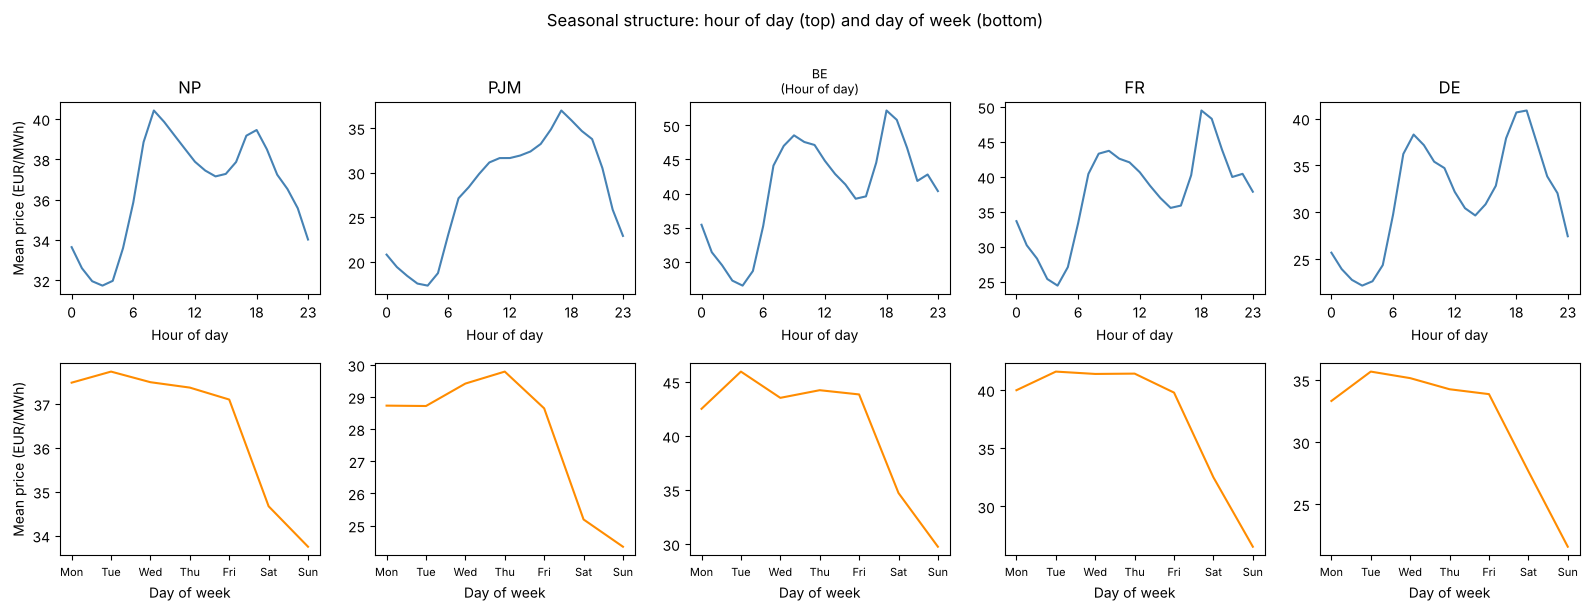

In [10]:
fig, axes = plt.subplots(2, 5, figsize=(16, 6))
day_labels = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

for col, market in enumerate(markets):
    s = data[market]

    # Hour of day profile
    ax_h = axes[0, col]
    s.groupby(s.index.hour).mean().plot(ax=ax_h, color="steelblue", linewidth=1.5)
    ax_h.set_title(market)
    ax_h.set_xlabel("Hour of day")
    ax_h.set_xticks([0, 6, 12, 18, 23])
    if col == 0:
        ax_h.set_ylabel("Mean price (EUR/MWh)")

    # Day of week profile (0=Monday in pandas)
    ax_d = axes[1, col]
    s.groupby(s.index.dayofweek).mean().plot(ax=ax_d, color="darkorange", linewidth=1.5)
    ax_d.set_xlabel("Day of week")
    ax_d.set_xticks(range(7))
    ax_d.set_xticklabels(day_labels, fontsize=8)
    if col == 0:
        ax_d.set_ylabel("Mean price (EUR/MWh)")

axes[0, 2].set_title("BE\n(Hour of day)", fontsize=9)
fig.suptitle("Seasonal structure: hour of day (top) and day of week (bottom)", y=1.01)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/seasonal_structure.png", dpi=150, bbox_inches="tight")
plt.show()

### Key findings from seasonal structure

**Hour of day:** All markets show a clear daytime price premium over night hours, confirming the demand-driven pattern. European markets (NP, BE, FR, DE) show a **double-peak** structure — morning (~8–9h) and evening (~18–19h) — with a midday dip caused by solar generation injecting supply at peak irradiance. PJM shows a single broad afternoon peak, consistent with lower solar penetration in the US mid-Atlantic grid in 2016–2018.

**Day of week:** All markets show a clear weekday premium over weekends, driven by industrial and commercial demand. NP shows a softer Monday — a hydro market effect where weekend reservoir filling leads to cheap dispatch at the start of the week.

**Implication for forecasting:** These strong, predictable cycles are what forecasting models are primarily trained on. The harder problem — and the one relevant to our research — is forecasting the *deviations* from these cycles: the spikes and troughs that create tail risk. We examine where forecast errors concentrate in Phase 2.

## Step 4 — Cross-market dependence

If two markets are highly correlated, finding the same result in both is not two independent pieces of evidence — it is one. This matters for how strongly we can claim our findings replicate across markets.

We compute pairwise price correlations, but only on the **overlapping time window** for each pair. Correlating different time periods is meaningless — a high correlation might just reflect that both markets happened to have a similar trend in their respective years.

The overlapping windows are:
- BE ∩ FR: 2015-01-04 → 2016-12-31 (full overlap)
- DE ∩ BE and DE ∩ FR: 2016-01-04 → 2016-12-31 (partial overlap)
- NP ∩ PJM: 2016-12-27 → 2018-12-24 (full overlap)
- NP/PJM ∩ European markets: very limited or none

We use `pd.concat` with `join="inner"` which automatically keeps only the rows where both series have a timestamp — the intersection.

In [11]:
from itertools import combinations

# Load all markets as a dict of price series
prices = {}
for market in markets:
    path = f"{DATA_DIR}/Forecasts_{market}_DNN_LEAR_ensembles.csv"
    prices[market] = pd.read_csv(path, index_col=0, parse_dates=True)["Real price"]

# Compute pairwise correlations on overlapping windows only
rows = []
for m1, m2 in combinations(markets, 2):
    combined = pd.concat([prices[m1], prices[m2]], axis=1, join="inner")
    combined.columns = [m1, m2]
    n_overlap = len(combined)
    corr = combined[m1].corr(combined[m2])
    rows.append({
        "Pair":          f"{m1} — {m2}",
        "Overlap (hrs)": n_overlap,
        "Overlap (days)": n_overlap // 24,
        "Correlation":   round(corr, 3),
    })

corr_df = pd.DataFrame(rows).set_index("Pair")
corr_df.sort_values("Correlation", ascending=False)

,Overlap (hrs),Overlap (days),Correlation
Pair,,,
BE — FR,17472,728,0.791
PJM — BE,120,5,0.776
PJM — FR,120,5,0.712
NP — BE,120,5,0.658
BE — DE,8712,363,0.608
FR — DE,8712,363,0.574
NP — DE,8880,370,0.568
NP — FR,120,5,0.372
PJM — DE,8880,370,0.235


### Key findings from cross-market dependence

**Pairs with fewer than 30 days of overlap should be disregarded** — 5 days is far too little to estimate a stable correlation. This eliminates all pairs involving NP or PJM with European markets.

**Meaningful correlations:**
- **BE — FR: 0.791** (728 days) — very high. These two markets are nearly one data point.
- **BE — DE: 0.608**, **FR — DE: 0.574** (363 days) — moderate. DE is partially linked to the BE/FR cluster through the interconnected European grid.
- **NP — PJM: 0.232** (728 days) — low. These are the two genuinely independent markets.

**Implication for the thesis:** The "five markets" framing overstates the evidence. The dataset is better described as:
- **Cluster 1**: BE and FR (nearly one data point)
- **Cluster 2**: DE (partially linked to Cluster 1)
- **Independent**: NP and PJM (two separate data points)

Any claim of the form "confirmed across five markets" should be qualified: we have roughly 3–4 degrees of market independence, not 5. This limits how strongly replication can be claimed.

---

## Phase 1 — Conclusion

We have examined the raw price data across all five markets before looking at a single forecast. Here is what we learned and why each finding carries forward into the analysis.

### What we found

**1. Data is clean.** All five markets have complete hourly grids, no missing values, no duplicate timestamps. The data was likely stored in UTC, avoiding daylight saving ambiguities. We can trust the files.

**2. Test windows are not aligned.** BE and FR cover 2015–2016, DE covers 2016–2017, NP and PJM cover 2016–2018. No single calendar period is shared by all five markets. Cross-market comparisons confound market structure with time period effects — they cannot be cleanly separated.

**3. Price distributions are fat-tailed and right-skewed.** Every market has excess kurtosis well above zero — extreme price events are far more common than a normal distribution would predict. FR (kurtosis 522) and BE (147) are dominated by nuclear outage spikes reaching 696–874 EUR/MWh. DE is the exception: near-zero skewness because extreme negative prices (−130 EUR/MWh from renewable oversupply) balance the right tail.

**4. Strong and predictable seasonal structure.** Hour-of-day and day-of-week cycles are clear in every market. European markets show a midday solar dip creating a double daily peak; PJM does not. These cycles are what models are primarily trained to forecast — the residual deviations (spikes, troughs) are the hard part.

**5. The five markets are not five independent data points.** BE and FR are correlated at 0.791 over their full shared window — nearly one data point. DE is moderately linked to both (0.59). NP and PJM are weakly correlated with each other (0.23) and have too little overlap with European markets to assess. Effective independence: roughly 3 clusters, not 5.

### What this means for the thesis

- **Analyse each market on its own terms first.** Do not pool or rank across markets without accounting for the different time periods.
- **CVaR in FR and BE will be dominated by a small number of extreme spike hours.** A risk-averse buyer in those markets faces a qualitatively different problem than in DE or NP.
- **Claims of replication across "five markets" must be qualified.** The honest framing is: two independent markets (NP, PJM), one BE/FR cluster, and DE partially linked to that cluster.
- **The seasonal structure tells us what models find easy.** Phase 2 will tell us what they find hard — and whether that hard part is exactly where the risk-averse buyer is most exposed.

---

# Phase 2 — Where Does Forecast Error Live?

This is the analytical crux of the thesis. We have confirmed that price distributions are fat-tailed and right-skewed. Now we ask: do forecast models make their worst errors precisely in the tail — the expensive, unusual hours that a risk-averse buyer cares most about?

We examine two distinct questions:

**Question 1 — Magnitude:** Is absolute error larger in the tail than in ordinary hours? A model could have uniformly distributed errors (equally wrong everywhere) or concentrated errors (much worse during spikes). We compare against a uniform benchmark: if error were perfectly uniform, every decile would show the same MAE.

**Question 2 — Direction (signed bias):** When errors occur in the tail, do they go in a consistent direction? A model that consistently *under-forecasts* spikes will cause a risk-averse buyer to systematically under-estimate tail risk — the most dangerous failure mode. A model that sometimes over- and sometimes under-forecasts has large but unbiased errors that partially cancel.

**Why direction matters more for our research question:**  
The buyer computes M_λ = (1−λ)·E[p] + λ·CVaR_α[p] to decide whether to fix or float. If the forecast consistently under-estimates the tail, M_λ will be too low, the buyer will under-hedge, and the cost of that mistake falls precisely during expensive hours. Unbiased errors are noisy but not systematically dangerous. Biased errors in the tail are.

## Method: binning by realised price decile

We divide all hours into 10 equal-sized bins (deciles) based on the **realised price** — not the forecast. Decile 1 is the cheapest 10% of hours; decile 10 is the most expensive 10%.

For each decile we compute:
- **Mean Absolute Error (MAE)**: average size of error, regardless of direction
- **Mean Signed Error (MSE)**: average of (forecast − actual). Positive = model over-forecasts on average; negative = model under-forecasts on average.

We do this for both DNN Ensemble and LEAR Ensemble, starting with NP.

In [12]:
df_np = pd.read_csv(
    f"{DATA_DIR}/Forecasts_NP_DNN_LEAR_ensembles.csv",
    index_col=0, parse_dates=True
)

# Assign each hour to a price decile based on the realised price
df_np["decile"] = pd.qcut(df_np["Real price"], q=10, labels=False) + 1  # 1–10

# Compute MAE and signed error per decile for each ensemble
results = []
for decile in range(1, 11):
    mask = df_np["decile"] == decile
    subset = df_np[mask]
    actual = subset["Real price"]

    for model in ["DNN Ensemble", "LEAR Ensemble"]:
        error = subset[model] - actual
        results.append({
            "Decile":       decile,
            "Model":        model,
            "Price range":  f"{actual.min():.1f}–{actual.max():.1f}",
            "MAE":          round(error.abs().mean(), 3),
            "Signed error": round(error.mean(), 3),   # positive = over-forecast
        })

decile_df = pd.DataFrame(results)

# Overall MAE as the uniform benchmark
overall_mae_dnn  = (df_np["DNN Ensemble"]  - df_np["Real price"]).abs().mean()
overall_mae_lear = (df_np["LEAR Ensemble"] - df_np["Real price"]).abs().mean()
print(f"Overall MAE — DNN: {overall_mae_dnn:.3f} | LEAR: {overall_mae_lear:.3f}")
print("(This is the uniform benchmark: if error were equal across deciles, every row would show this value)\n")

decile_df.pivot(index="Decile", columns="Model", values=["MAE", "Signed error"])

Overall MAE — DNN: 1.683 | LEAR: 1.738
(This is the uniform benchmark: if error were equal across deciles, every row would show this value)



MAE               Signed error              
Model  DNN Ensemble LEAR Ensemble DNN Ensemble LEAR Ensemble
Decile                                                      
1             2.268         2.203        1.310         1.276
2             0.824         0.837        0.056         0.037
3             0.833         0.862        0.004         0.038
4             0.877         0.999        0.047         0.218
5             1.109         1.180        0.038         0.349
6             1.698         1.601       -0.337        -0.135
7             1.922         2.012       -0.961        -0.964
8             1.885         1.949       -0.800        -0.696
9             1.900         2.001       -1.043        -0.926
10            3.515         3.731       -2.671        -2.513

## Visualising error by price decile

Two plots side by side:

**Left — MAE by decile** with the overall MAE drawn as a horizontal dashed line (the uniform benchmark). Bars above the line mean the model is *more* wrong in that decile than average; bars below mean it is *less* wrong. If error were perfectly uniform, all bars would touch the line.

**Right — Signed error by decile** (forecast − actual). A positive bar means the model over-forecasts on average in that decile — it predicted a higher price than realised. A negative bar means under-forecasting — the model predicted a lower price than realised. The zero line is the boundary between the two biases.

The pattern in the signed error is the key finding: if it is positive in cheap deciles and negative in expensive deciles, the model is systematically **pulled toward the mean** — over-estimating cheap hours and under-estimating expensive ones. This is a known consequence of training on squared error, which rewards predicting the conditional mean.

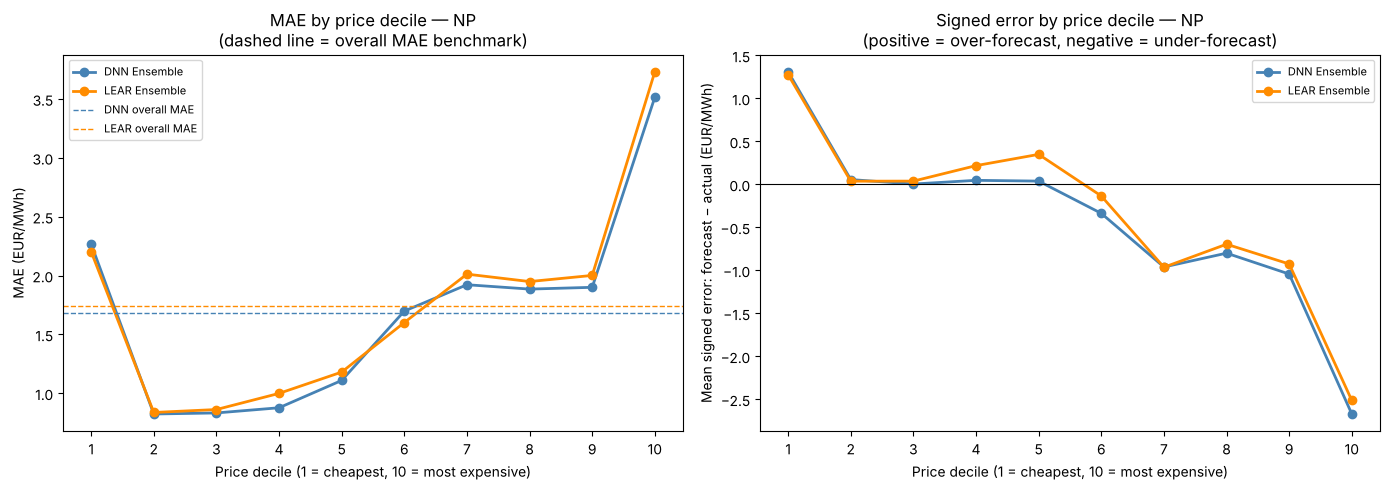

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x = list(range(1, 11))
colors = {"DNN Ensemble": "steelblue", "LEAR Ensemble": "darkorange"}

# --- Left: MAE by decile ---
ax = axes[0]
for model in ["DNN Ensemble", "LEAR Ensemble"]:
    vals = decile_df[decile_df["Model"] == model]["MAE"].values
    ax.plot(x, vals, marker="o", linewidth=2, label=model, color=colors[model])

ax.axhline(overall_mae_dnn,  color="steelblue",  linestyle="--", linewidth=1, label="DNN overall MAE")
ax.axhline(overall_mae_lear, color="darkorange", linestyle="--", linewidth=1, label="LEAR overall MAE")
ax.set_xlabel("Price decile (1 = cheapest, 10 = most expensive)")
ax.set_ylabel("MAE (EUR/MWh)")
ax.set_title("MAE by price decile — NP\n(dashed line = overall MAE benchmark)")
ax.set_xticks(x)
ax.legend(fontsize=8)

# --- Right: Signed error by decile ---
ax = axes[1]
for model in ["DNN Ensemble", "LEAR Ensemble"]:
    vals = decile_df[decile_df["Model"] == model]["Signed error"].values
    ax.plot(x, vals, marker="o", linewidth=2, label=model, color=colors[model])

ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Price decile (1 = cheapest, 10 = most expensive)")
ax.set_ylabel("Mean signed error: forecast − actual (EUR/MWh)")
ax.set_title("Signed error by price decile — NP\n(positive = over-forecast, negative = under-forecast)")
ax.set_xticks(x)
ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/error_by_decile_NP.png", dpi=150, bbox_inches="tight")
plt.show()

### Interpretation — NP error anatomy

**MAE plot: U-shaped, not uniform.**  
Error is not evenly distributed across the price distribution. The cheapest hours (decile 1) and the most expensive hours (decile 10) have the highest absolute errors — more than double the overall MAE benchmark (dashed line). The middle deciles (2–5) are where models perform best. The overall MAE of ~1.68 (DNN) sits in the middle of this U, masking the fact that tail-hour error is roughly 3.5 EUR/MWh — twice that figure.

**Signed error plot: systematic regression to the mean.**  
Both models over-forecast in cheap hours (deciles 1–5, positive signed error) and under-forecast in expensive hours (deciles 6–10, negative signed error). In decile 10, the under-forecast is approximately −2.5 to −2.7 EUR/MWh on average.

This pattern is called **regression to the mean** — a structural consequence of training on squared error. Squared-error minimisation rewards predicting the conditional mean of the distribution. When realised prices deviate far from the mean (either very cheap or very expensive), the forecast is pulled back toward average, creating systematic bias at the extremes.

**The implication for a risk-averse buyer:**  
A buyer using these forecasts to estimate M_λ = (1−λ)·E[p] + λ·CVaR_α[p] will systematically under-estimate the tail. The forecast says the worst hours will cost around X EUR/MWh — but realised prices are consistently X + 2.5. The buyer under-hedges, and the mistake lands precisely in the most expensive hours. This is not random noise that averages out — it is a structural bias that gets worse as risk aversion increases.

**This is the core finding of Phase 2.** We now check whether this pattern holds across all five markets.

> **Correction (14 Oct 2026).** Grouping hours by realised price is a selection effect: hours chosen because the price ended high are hours with large positive shocks, so even a perfect forecast of the conditional mean looks biased downward there. Grouped by forecast decile, the top-decile bias is much smaller (NP: −1.0 EUR/MWh for the DNN, −0.6 for LEAR). The conclusions below about a structural tail bias that makes the buyer under-hedge do not hold as stated; see the mechanism checks at the end of this notebook.

## Error anatomy — all five markets

We repeat the decile analysis across all five markets. The key question: is the regression-to-the-mean bias in the tail a property of NP specifically, or does it appear consistently everywhere?

For FR and BE — which have extreme kurtosis and nuclear spike events — we expect the tail signed error to be substantially larger in magnitude, because the spikes are far more extreme and the model's pull toward the mean will be even stronger.

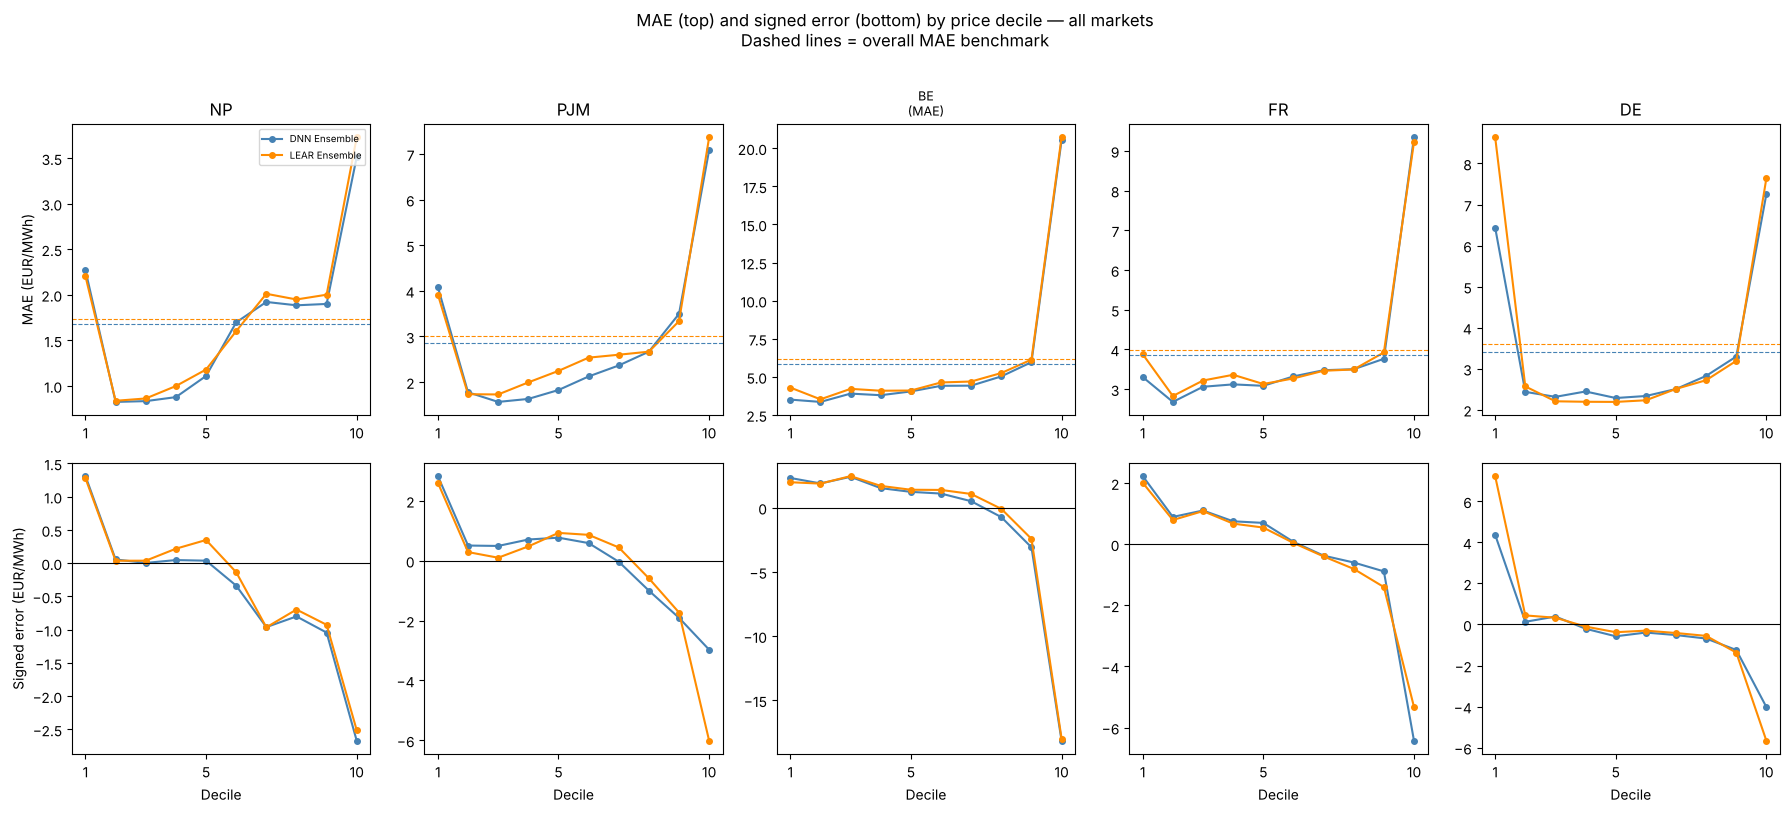

In [14]:
fig, axes = plt.subplots(2, 5, figsize=(18, 8))
x = list(range(1, 11))
colors = {"DNN Ensemble": "steelblue", "LEAR Ensemble": "darkorange"}

for col, market in enumerate(markets):
    path = f"{DATA_DIR}/Forecasts_{market}_DNN_LEAR_ensembles.csv"
    d = pd.read_csv(path, index_col=0, parse_dates=True)
    d["decile"] = pd.qcut(d["Real price"], q=10, labels=False) + 1

    overall = {
        "DNN Ensemble":  (d["DNN Ensemble"]  - d["Real price"]).abs().mean(),
        "LEAR Ensemble": (d["LEAR Ensemble"] - d["Real price"]).abs().mean(),
    }

    mae_vals  = {m: [] for m in colors}
    sign_vals = {m: [] for m in colors}

    for dec in range(1, 11):
        subset = d[d["decile"] == dec]
        actual = subset["Real price"]
        for model in colors:
            err = subset[model] - actual
            mae_vals[model].append(err.abs().mean())
            sign_vals[model].append(err.mean())

    # MAE plot
    ax = axes[0, col]
    for model in colors:
        ax.plot(x, mae_vals[model], marker="o", linewidth=1.5,
                markersize=4, label=model, color=colors[model])
    ax.axhline(overall["DNN Ensemble"],  color="steelblue",  linestyle="--", linewidth=0.8)
    ax.axhline(overall["LEAR Ensemble"], color="darkorange", linestyle="--", linewidth=0.8)
    ax.set_title(market)
    ax.set_xticks([1, 5, 10])
    if col == 0:
        ax.set_ylabel("MAE (EUR/MWh)")

    # Signed error plot
    ax = axes[1, col]
    for model in colors:
        ax.plot(x, sign_vals[model], marker="o", linewidth=1.5,
                markersize=4, label=model, color=colors[model])
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xticks([1, 5, 10])
    ax.set_xlabel("Decile")
    if col == 0:
        ax.set_ylabel("Signed error (EUR/MWh)")

axes[0, 2].set_title("BE\n(MAE)", fontsize=9)
axes[0, 0].legend(fontsize=7, loc="upper right")
fig.suptitle("MAE (top) and signed error (bottom) by price decile — all markets\n"
             "Dashed lines = overall MAE benchmark", y=1.01)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/error_by_decile_all.png", dpi=150, bbox_inches="tight")
plt.show()

---

## Phase 2 — Conclusion

### What we found

**1. MAE is not uniformly distributed — but the shape differs by market.**

- **FR and BE**: Hockey-stick shape. MAE is low across deciles 1–9 and spikes dramatically at decile 10. The tail error (from nuclear outage spikes) is an order of magnitude larger than middle-decile error. The overall MAE benchmark completely hides this.
- **DE**: Pronounced U-shape. Both decile 1 (extreme negative prices, −130 EUR/MWh minimum) and decile 10 (positive spikes) show large errors. This reflects DE's two-sided tail structure identified in Phase 1.
- **NP and PJM**: Moderate U-shape. Both tails are problematic but less extreme than FR/BE.

**2. Systematic regression-to-the-mean bias — universal across all five markets.**

Every market shows the same directional pattern in the signed error:
- **Cheap hours (deciles 1–5)**: models over-forecast (positive signed error) — pulled upward toward the mean
- **Expensive hours (deciles 6–10)**: models under-forecast (negative signed error) — pulled downward toward the mean

This is a structural consequence of squared-error training, not a model-specific failure. Both DNN and LEAR show the same direction and similar magnitudes. In decile 10, the under-forecast ranges from approximately −2.5 EUR/MWh (NP) to −15 EUR/MWh (FR/BE).

### What this means for the thesis

**The overall MAE is a misleading summary statistic for a risk-averse buyer.** It averages over all deciles, including the cheap middle hours where models perform well, masking severe under-performance in the tail.

**The bias in the tail is structural and directional.** A risk-averse buyer computing CVaR from these forecasts will systematically under-estimate the expected cost in the worst hours. This is not random noise — it is a predictable consequence of how the models are trained. The buyer will under-hedge, and the cost of that mistake falls precisely in the most expensive hours.

**This directly supports the thesis hypothesis:** as risk aversion λ increases, the buyer's decision depends more heavily on the tail — the exact region where accuracy-trained forecasts are most biased. The misalignment between training loss (MAE) and decision loss (regret under CVaR) should therefore grow with λ.

---

> **Correction (14 Oct 2026).** Grouping hours by realised price is a selection effect: hours chosen because the price ended high are hours with large positive shocks, so even a perfect forecast of the conditional mean looks biased downward there. Grouped by forecast decile, the top-decile bias is much smaller (NP: −1.0 EUR/MWh for the DNN, −0.6 for LEAR). The conclusions below about a structural tail bias that makes the buyer under-hedge do not hold as stated; see the mechanism checks at the end of this notebook.

---

## The Story So Far — Connecting Phase 1 and Phase 2 to the Research Question

Before moving forward, it is worth stepping back and reading what we have found as a coherent narrative.

---

### What we set out to test

The thesis asks: *as a buyer becomes more risk-averse, does the model that is most accurate by standard metrics also produce the best decisions — or do accuracy rankings and decision rankings diverge?*

The theoretical answer is clear: at λ=0 (risk-neutral), accuracy-trained models are decision-optimal by construction. As λ increases, the decision depends on M_λ = (1−λ)·E[p] + λ·CVaR_α[p] — a quantity that shifts into the upper tail. No standard accuracy metric weights the tail preferentially. So misalignment *should* grow with λ.

But theory does not tell us how large the gap is in practice. That is an empirical question.

---

### What the data told us

**Phase 1** established the landscape:
- Electricity prices are fat-tailed and right-skewed. Extreme events are far more common than a normal distribution predicts.
- FR and BE are dominated by nuclear outage spikes — their tail is concentrated in a handful of catastrophic hours.
- DE has a two-sided tail (renewable negative prices + spikes), making it structurally different.
- The five markets are not five independent data points — BE and FR move together at 0.79 correlation. We have roughly 3 independent clusters.

**Phase 2** showed where forecast models fail:
- Both DNN and LEAR under-forecast expensive hours and over-forecast cheap hours — a structural regression-to-the-mean bias caused by squared-error training.
- The bias is not random noise. It is directional, consistent across all five markets, and largest in the exact hours a risk-averse buyer cares most about.
- The overall MAE conceals this: by averaging over all hours including the well-forecast middle deciles, it makes models look better than they are precisely where it matters.

---

### Why this matters

A risk-averse buyer computing CVaR from these forecasts will:
1. **Underestimate the tail** — the forecast says expensive hours will cost X, but they consistently cost X + something
2. **Under-hedge as a result** — choosing to float on the spot market precisely when it is most costly to do so
3. **Face a growing gap** as λ increases — because higher risk aversion shifts the decision entirely into the tail region where the bias is largest

This is no longer just a theoretical prediction. Phases 1 and 2 have shown that the structural conditions for misalignment exist in the data. Phase 3 will quantify whether the predictive intervals we can build from these forecasts are calibrated — or whether the tail is even worse than the signed error analysis suggests.

---

> **Correction (14 Oct 2026).** Grouping hours by realised price is a selection effect: hours chosen because the price ended high are hours with large positive shocks, so even a perfect forecast of the conditional mean looks biased downward there. Grouped by forecast decile, the top-decile bias is much smaller (NP: −1.0 EUR/MWh for the DNN, −0.6 for LEAR). The conclusions below about a structural tail bias that makes the buyer under-hedge do not hold as stated; see the mechanism checks at the end of this notebook.

# Phase 3 — From Point Forecasts to Distributions

## The problem

The decision model requires M_λ = (1−λ)·E[p] + λ·CVaR_α[p]. CVaR is a property of a distribution — not a point forecast. We only have point forecasts in the CSV files. We need to construct a predictive distribution from them.

## The method: rolling empirical residual distribution (thesis eq. 3.5)

1. For each hour t, collect the **residuals** (actual − forecast) of the **previous 90 days** (2,160 hours).
2. The empirical distribution of those past residuals is our estimate of today's forecast uncertainty.
3. The predictive distribution for the price at hour t is that residual distribution shifted by the point forecast: `predicted price = point forecast + past residual`.

So if the model forecasts 40 EUR/MWh and past residuals ranged from −10 to +15, the predictive distribution spans roughly 30 to 55 EUR/MWh. A positive residual means the price came out above the forecast, so past price spikes populate the **upper** tail.

**A prediction interval** at nominal coverage (1−α) keeps the middle (1−α) of that distribution:
- Lower bound: point forecast + α/2 quantile of past residuals
- Upper bound: point forecast + (1−α/2) quantile of past residuals

## What calibration means

A **calibrated** 80 % interval contains the realised price 80 % of the time. We check this:
- **Overall**: across all evaluation hours
- **In the tail**: here restricted to the top decile of realised prices (selection-biased, see the mechanism checks at the end of the notebook, which group by forecast instead)

We test 80 % and 90 % nominal coverage, using the DNN Ensemble on NP first.

In [15]:
import numpy as np

df_np = pd.read_csv(
    f"{DATA_DIR}/Forecasts_NP_DNN_LEAR_ensembles.csv",
    index_col=0, parse_dates=True
)

WINDOW = 90 * 24   # 90 days of hourly errors
model  = "DNN Ensemble"

errors = df_np["Real price"] - df_np[model]   # residual: actual − forecast (eq. 3.5)

lower_80, upper_80 = [], []
lower_90, upper_90 = [], []

for t in range(WINDOW, len(df_np)):
    past_errors = errors.iloc[t - WINDOW : t].values
    forecast_t  = df_np[model].iloc[t]

    # 80% interval: keep middle 80%, drop 10% from each tail
    lower_80.append(forecast_t + np.percentile(past_errors, 10))
    upper_80.append(forecast_t + np.percentile(past_errors, 90))

    # 90% interval: keep middle 90%, drop 5% from each tail
    lower_90.append(forecast_t + np.percentile(past_errors, 5))
    upper_90.append(forecast_t + np.percentile(past_errors, 95))

# Align with the part of the data we have intervals for
eval_df = df_np.iloc[WINDOW:].copy()
actual  = eval_df["Real price"].values

# Coverage: fraction of hours where actual falls inside the interval
in_80 = (actual >= lower_80) & (actual <= upper_80)
in_90 = (actual >= lower_90) & (actual <= upper_90)

# Tail: top decile of realised prices
tail_mask = actual >= np.percentile(actual, 90)

print("=== NP — DNN Ensemble ===")
print(f"\n80% nominal interval:")
print(f"  Overall coverage:  {in_80.mean():.3f}  (target: 0.800)")
print(f"  Tail coverage:     {in_80[tail_mask].mean():.3f}  (target: 0.800)")

print(f"\n90% nominal interval:")
print(f"  Overall coverage:  {in_90.mean():.3f}  (target: 0.900)")
print(f"  Tail coverage:     {in_90[tail_mask].mean():.3f}  (target: 0.900)")

=== NP — DNN Ensemble ===

80% nominal interval:
  Overall coverage:  0.775  (target: 0.800)
  Tail coverage:     0.652  (target: 0.800)

90% nominal interval:
  Overall coverage:  0.878  (target: 0.900)
  Tail coverage:     0.774  (target: 0.900)


## Calibration — all five markets

The NP result shows a large gap between overall and tail coverage. We now check whether this holds across all five markets for both ensembles.

We expect the gap to be largest in FR and BE — where the tail is dominated by extreme nuclear spikes that are far outside the rolling error window, making the upper bound of the interval structurally too low.

In [16]:
WINDOW = 90 * 24
rows = []

for market in markets:
    path = f"{DATA_DIR}/Forecasts_{market}_DNN_LEAR_ensembles.csv"
    d = pd.read_csv(path, index_col=0, parse_dates=True)

    for model in ["DNN Ensemble", "LEAR Ensemble"]:
        errors = d["Real price"] - d[model]   # residual: actual − forecast (eq. 3.5)

        lower_80, upper_80 = [], []
        lower_90, upper_90 = [], []

        for t in range(WINDOW, len(d)):
            past_errors = errors.iloc[t - WINDOW : t].values
            forecast_t  = d[model].iloc[t]
            lower_80.append(forecast_t + np.percentile(past_errors, 10))
            upper_80.append(forecast_t + np.percentile(past_errors, 90))
            lower_90.append(forecast_t + np.percentile(past_errors, 5))
            upper_90.append(forecast_t + np.percentile(past_errors, 95))

        actual    = d["Real price"].iloc[WINDOW:].values
        tail_mask = actual >= np.percentile(actual, 90)
        in_80 = (actual >= lower_80) & (actual <= upper_80)
        in_90 = (actual >= lower_90) & (actual <= upper_90)

        rows.append({
            "Market":           market,
            "Model":            model,
            "80% overall":      round(in_80.mean(), 3),
            "80% tail":         round(in_80[tail_mask].mean(), 3),
            "80% gap":          round(in_80.mean() - in_80[tail_mask].mean(), 3),
            "90% overall":      round(in_90.mean(), 3),
            "90% tail":         round(in_90[tail_mask].mean(), 3),
            "90% gap":          round(in_90.mean() - in_90[tail_mask].mean(), 3),
        })

cal_df = pd.DataFrame(rows).set_index(["Market", "Model"])
cal_df

80% overall  80% tail  80% gap  90% overall  90% tail  \
Market Model                                                                  
NP     DNN Ensemble         0.775     0.652    0.123        0.878     0.774   
       LEAR Ensemble        0.781     0.656    0.125        0.882     0.780   
PJM    DNN Ensemble         0.785     0.420    0.365        0.883     0.582   
       LEAR Ensemble        0.779     0.463    0.316        0.882     0.614   
BE     DNN Ensemble         0.783     0.472    0.311        0.884     0.625   
       LEAR Ensemble        0.779     0.463    0.316        0.885     0.631   
FR     DNN Ensemble         0.787     0.586    0.201        0.887     0.719   
       LEAR Ensemble        0.785     0.567    0.218        0.885     0.691   
DE     DNN Ensemble         0.789     0.549    0.240        0.883     0.692   
       LEAR Ensemble        0.781     0.523    0.259        0.882     0.682   

                      90% gap  
Market Model                   
NP     DNN Ensemble     0.105  
       LEAR Ensemble    0.102  
PJM    DNN Ensemble     0.301  
       LEAR Ensemble    0.268  
BE     DNN Ensemble     0.259  
       LEAR Ensemble    0.254  
FR     DNN Ensemble     0.168  
       LEAR Ensemble    0.194  
DE     DNN Ensemble     0.191  
       LEAR Ensemble    0.201

---

## Phase 3 — Conclusion

### What we found

| Market | 80 % coverage, all hours (DNN / LEAR) | 80 % coverage, top realised decile* (DNN / LEAR) |
|---|---|---|
| NP  | 77.5 / 78.1 | 65.2 / 65.6 |
| PJM | 78.5 / 77.9 | 42.0 / 46.3 |
| BE  | 78.3 / 77.9 | 47.2 / 46.3 |
| FR  | 78.7 / 78.5 | 58.6 / 56.7 |
| DE  | 78.9 / 78.1 | 54.9 / 52.3 |

\* selection-biased: hours chosen because the price ended high.

- Over all hours the intervals are close to nominal (77.5–78.9 % for a nominal 80 %).
- Restricted to the hours where the price **ended** high, coverage drops to 42–66 %. This restriction selects the hours with the largest positive shocks, so it overstates the problem. The selection-free check (hours grouped by **forecast**, in the mechanism checks at the end of this notebook) shows that when a high price is forecast, the price exceeds the predicted 90th percentile in 13.8–26.8 % of hours instead of 10 %: tail risk is under-estimated, but less than the realised-decile figures suggest.

> **Correction (14 Oct 2026).** The earlier version of this table (38–57 % tail coverage) used the mirrored predictive distribution and the realised-price selection; both are corrected here.

# Phase 4 — The Decision Model

## What we are building and why

Phases 1–3 were diagnostic: we looked at the data, the forecast errors, and the calibration of predictive intervals. We found structural problems — regression-to-the-mean bias and tail miscalibration — that suggest forecasts will mislead a risk-averse buyer.

Phase 4 tests this directly. We implement the actual hedging decision, compute what the buyer would have done using each forecast, and compare it to what they *should* have done with perfect foresight. The gap is **regret** — the cost of using a forecast instead of knowing the future.

The central question: **does regret grow as risk aversion λ increases?** If yes, it confirms the thesis hypothesis. If no, the structural failures we found in Phases 2–3 do not translate into worse decisions — a genuine null result.

---

## The decision structure

An industrial electricity buyer must decide, before the spot market clears, what share `z ∈ [0, 1]` of their consumption to lock in at a forward price `f`. They buy the remaining `(1−z)` share at the realised spot price `p`.

Their total cost per unit of consumption is:

$$\text{cost}(z) = f \cdot z + p \cdot (1 - z)$$

This is simply a weighted average of the forward price and the spot price. If `z = 1`, they pay the forward price for everything. If `z = 0`, they pay spot for everything.

---

## Why the optimal decision is bang-bang

The buyer minimises a risk-adjusted objective that blends expected cost and tail risk (CVaR):

$$\rho_\lambda = (1 - \lambda) \cdot \mathbb{E}[\text{cost}] + \lambda \cdot \text{CVaR}_\alpha[\text{cost}]$$

Because cost is **linear (affine) in `z`**, the objective is also linear in `z`. A linear function over the interval [0, 1] is always minimised at one of the endpoints — either `z = 0` or `z = 1`. There is never a reason to choose `z = 0.5`.

Think of it this way: if the forward price is cheaper than what you expect to pay on the spot market (adjusted for risk aversion), you should fix *everything*. If the forward price is more expensive, you should fix *nothing*. A partial hedge would mean paying the expensive forward price for some consumption when you didn't have to — or missing out on the cheap forward price for some consumption when you should have taken it.

Mathematically, the optimal decision reduces to:

$$z^* = \begin{cases} 1 & \text{if } f < M_\lambda \\ 0 & \text{if } f > M_\lambda \end{cases}$$

where $M_\lambda = (1 - \lambda) \cdot \mathbb{E}[p] + \lambda \cdot \text{CVaR}_\alpha[p]$ is the **risk-adjusted expected spot price**.

- At **λ = 0** (risk-neutral): $M_0 = \mathbb{E}[p]$ — fix if the forward is cheaper than the expected spot price
- At **λ = 1** (fully risk-averse): $M_1 = \text{CVaR}_\alpha[p]$ — fix if the forward is cheaper than the expected cost in the worst α% of scenarios

As λ increases, M_λ shifts into the upper tail. A more risk-averse buyer is willing to pay more for the certainty of the forward price.

---

## The forward price proxy

The actual forward price `f` (e.g. EEX day-ahead forward settlements) is paywalled. We construct a proxy:

$$f_t = \bar{p}_{t-N} \cdot (1 + \pi)$$

where $\bar{p}_{t-N}$ is the rolling mean of the past N days of realised prices, and $\pi$ is a **forward premium** — the extra cost buyers typically pay for price certainty. We use N = 90 days and π = 5% as our baseline, but we will test sensitivity to both.

This is a simplification. Real forward prices embed risk premia that vary over time. But for the purpose of testing whether forecast quality affects decision quality, the exact level of `f` matters less than its relationship to M_λ — which is what drives `z*`.

---

## How we compute M_λ from a point forecast

We only have point forecasts, not distributions. As in Phase 3, we use the rolling empirical residual distribution (past 90 days of residuals, actual − forecast) shifted by the point forecast (eq. 3.5) to construct a predictive distribution for the spot price.

From that distribution we extract:
- $\mathbb{E}[p]$: the mean of the predictive distribution = point forecast + mean past residual
- $\text{CVaR}_\alpha[p]$: the expected value in the worst α% of the predictive distribution

We use α = 10% (CVaR at the 90th percentile) as our baseline.

Then: $M_\lambda = (1-\lambda) \cdot \mathbb{E}[p] + \lambda \cdot \text{CVaR}_{0.10}[p]$

---

## What is regret?

**Regret** is the extra cost the buyer pays compared to what they would have paid with perfect foresight.

With perfect foresight, the buyer knows `p` before deciding:
- If `p < f`: buy everything spot (`z_oracle = 0`), cost = p
- If `p > f`: fix everything at forward (`z_oracle = 1`), cost = f

With a forecast, the buyer uses `z*(λ)` based on M_λ:
- If `z*(λ) = 1` but `p < f`: over-hedged, paid forward when spot was cheaper, regret = f − p
- If `z*(λ) = 0` but `p > f`: under-hedged, paid spot when forward was cheaper, regret = p − f
- If `z*(λ) = z_oracle`: correct decision, regret = 0

$$\text{regret}_t(\lambda) = \text{cost}(z^*_t(\lambda)) - \text{cost}(z^{\text{oracle}}_t)$$

We compute mean regret over all hours for each λ ∈ {0, 0.1, 0.2, ..., 1.0} and for each model. Then we ask: does the ranking of models by regret match their ranking by MAE? Does agreement vary with λ?

---

## Step 1 — Build the forward price proxy and the predictive distribution

Before computing any decisions, we construct two ingredients for each hour:

**Forward price $f_t$:** Rolling 90-day mean of past realised prices, scaled up by a premium $\pi = 5\%$. This represents what a buyer would pay to lock in price certainty. We use NP first, then show sensitivity to $\pi$.

**Predictive distribution:** The same rolling 90-day empirical residual distribution (actual − forecast) from Phase 3, shifted by the point forecast (eq. 3.5). From this we extract $\mathbb{E}[p]$ and $\text{CVaR}_{0.10}[p]$ (expected value in the worst 10% of the distribution).

We compute these for both DNN Ensemble and LEAR Ensemble, then for each $\lambda \in \{0, 0.1, ..., 1.0\}$ we derive $M_\lambda$, the optimal decision $z^*$, and the regret.

In [17]:
from decision_utils import WINDOW, ALPHA, PREMIUM, LAMBDAS, forward_proxy, compute_regret

df_np = pd.read_csv(f"{DATA_DIR}/Forecasts_NP_DNN_LEAR_ensembles.csv", index_col=0, parse_dates=True)

# --- Forward price proxy ---
# Rolling mean of the past WINDOW hours of realised prices, scaled up by (1 + PREMIUM)
f = forward_proxy(df_np["Real price"], WINDOW, PREMIUM)

# compute_regret (decision_utils.py), for each hour t after the 90-day burn-in:
#   - predictive distribution = forecast_t + residuals (actual − forecast) of the past 90 days (eq. 3.5)
#   - M_lambda = (1 − lambda) E[p] + lambda CVaR_alpha[p]
#   - z* = 1 if f < M_lambda (hedge), oracle z = 1 if f < actual
#   - regret = cost(z*) − cost(z_oracle)
print("Computing regret for DNN Ensemble...")
regret_dnn  = compute_regret(df_np, "DNN Ensemble",  f, WINDOW, ALPHA, LAMBDAS)
print("Computing regret for LEAR Ensemble...")
regret_lear = compute_regret(df_np, "LEAR Ensemble", f, WINDOW, ALPHA, LAMBDAS)

print(f"\nHours evaluated: {len(regret_dnn)}")
print("\nMean regret by λ:")
summary = pd.DataFrame({
    "DNN":  regret_dnn.mean(),
    "LEAR": regret_lear.mean(),
})
summary.index = [c.replace("regret_", "") for c in summary.index]
summary.round(4)

Computing regret for DNN Ensemble...


Computing regret for LEAR Ensemble...



Hours evaluated: 15312

Mean regret by λ:


,DNN,LEAR
λ=0.0,0.0907,0.0962
λ=0.1,0.1082,0.1143
λ=0.2,0.1581,0.1591
λ=0.3,0.2197,0.2173
λ=0.4,0.3034,0.3055
λ=0.5,0.3985,0.4054
λ=0.6,0.4936,0.5207
λ=0.7,0.6132,0.6394
λ=0.8,0.7381,0.7667
λ=0.9,0.8656,0.8908


## Step 2 — Plot regret vs $\lambda$

Two things to read from this plot:
- **Level**: how much regret grows as $\lambda$ increases — the absolute cost of using any forecast for a risk-averse decision
- **Gap**: how much the DNN–LEAR difference grows with $\lambda$ — the extra cost of choosing the worse model at high risk aversion

If the thesis hypothesis holds, both should increase with $\lambda$.

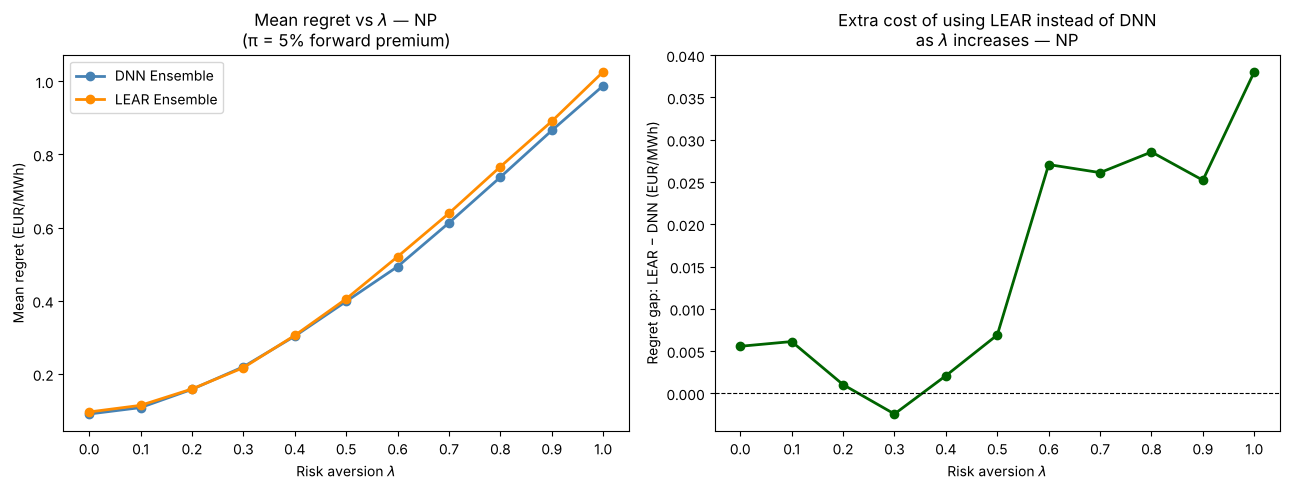

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
lam_vals = [float(c.split("=")[1]) for c in summary.index]

# --- Left: regret by λ for both models ---
ax = axes[0]
ax.plot(lam_vals, summary["DNN"],  marker="o", linewidth=2, color="steelblue",  label="DNN Ensemble")
ax.plot(lam_vals, summary["LEAR"], marker="o", linewidth=2, color="darkorange", label="LEAR Ensemble")
ax.set_xlabel("Risk aversion $\\lambda$")
ax.set_ylabel("Mean regret (EUR/MWh)")
ax.set_title("Mean regret vs $\\lambda$ — NP\n(π = 5% forward premium)")
ax.legend()
ax.set_xticks(lam_vals)

# --- Right: gap (LEAR − DNN) by λ ---
ax = axes[1]
gap = summary["LEAR"] - summary["DNN"]
ax.plot(lam_vals, gap, marker="o", linewidth=2, color="darkgreen")
ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_xlabel("Risk aversion $\\lambda$")
ax.set_ylabel("Regret gap: LEAR − DNN (EUR/MWh)")
ax.set_title("Extra cost of using LEAR instead of DNN\nas $\\lambda$ increases — NP")
ax.set_xticks(lam_vals)

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/regret_vs_lambda_NP.png", dpi=150, bbox_inches="tight")
plt.show()

### Interpretation — regret vs $\lambda$ on NP

**Left plot — regret rises with λ for both models.** Mean regret goes from 0.091 (DNN) and 0.096 (LEAR) EUR/MWh at λ = 0 to 0.988 and 1.026 at λ = 1. As λ grows, M_λ moves into the upper tail of the predictive distribution and the buyer hedges more often, including in hours where the spot price ends below the forward price.

**Right plot — the gap between the models stays small.** The gap (LEAR − DNN) is 0.006 EUR/MWh at λ = 0, close to zero between λ = 0.2 and 0.5 (slightly negative at λ = 0.3), and 0.038 at λ = 1. Whether these gaps are significant is tested in Phase 5.

**Caveat:** results depend on the forward premium π = 5 %; sensitivity follows.

> **Correction (14 Oct 2026).** The earlier version of this cell, computed with the mirrored predictive distribution, reported a dip in regret between λ = 0 and 0.2 and a gap growing to 0.097 EUR/MWh. Neither holds once the distribution follows eq. 3.5.

## Step 3 — Sensitivity to the forward premium $\pi$

The forward premium $\pi$ is a free parameter — we do not observe the true forward price. This creates a risk: if we only report results for one $\pi$ value that happens to favour a particular conclusion, the finding is not credible.

We test three values:
- **π = 0%**: forward = rolling mean. Forecast barely matters because M_λ > f at high λ almost always → buyer always hedges regardless of model.
- **π = 5%**: our baseline — forward sits slightly above the mean, in the range where forecasts actually change decisions.
- **π = 10%**: higher premium — buyer is less likely to hedge, forecast needs to identify the rare hours where hedging is still worth it.

**What to look for:** if the DNN–LEAR gap is consistent across all three premium values, the finding is robust. If it only appears at one specific $\pi$, it is an artifact of that choice.

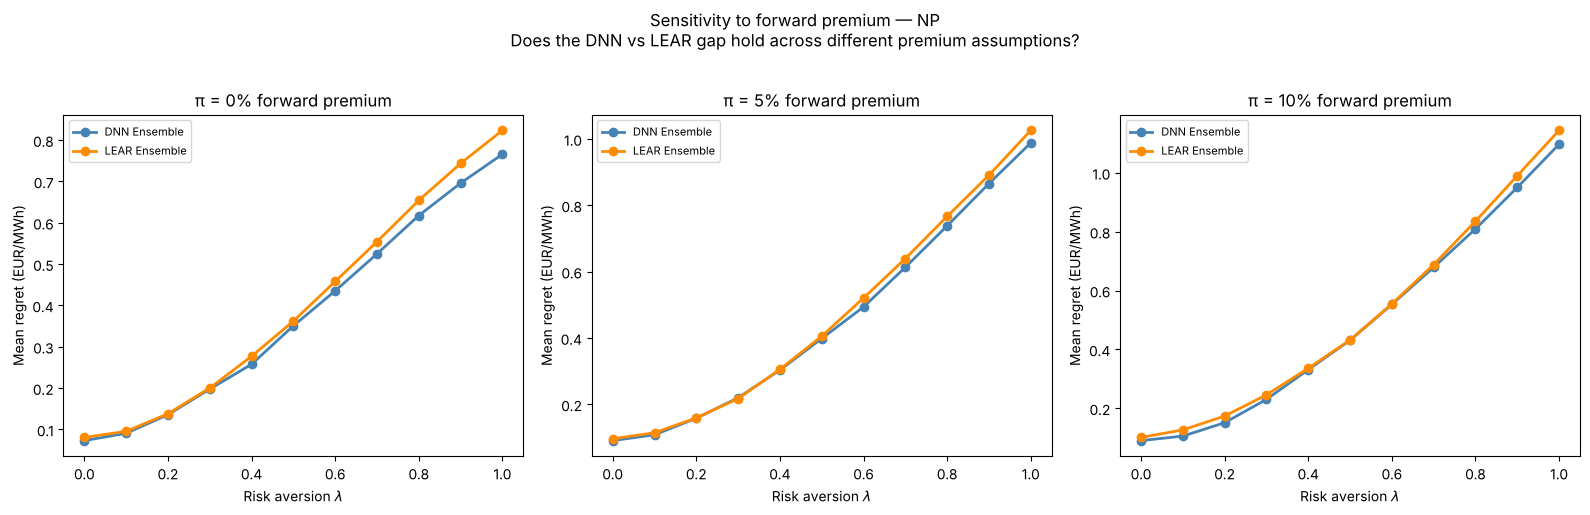

In [19]:
premiums = [0.00, 0.05, 0.10]
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=False)

for ax, pi in zip(axes, premiums):
    f_pi = df_np["Real price"].shift(1).rolling(WINDOW).mean() * (1 + pi)

    reg_dnn  = compute_regret(df_np, "DNN Ensemble",  f_pi, WINDOW, ALPHA, LAMBDAS)
    reg_lear = compute_regret(df_np, "LEAR Ensemble", f_pi, WINDOW, ALPHA, LAMBDAS)

    mean_dnn  = reg_dnn.mean()
    mean_lear = reg_lear.mean()
    lam_vals  = [float(c.split("=")[1]) for c in mean_dnn.index]

    ax.plot(lam_vals, mean_dnn.values,  marker="o", linewidth=2,
            color="steelblue",  label="DNN Ensemble")
    ax.plot(lam_vals, mean_lear.values, marker="o", linewidth=2,
            color="darkorange", label="LEAR Ensemble")
    ax.set_title(f"π = {int(pi*100)}% forward premium")
    ax.set_xlabel("Risk aversion $\\lambda$")
    ax.set_ylabel("Mean regret (EUR/MWh)")
    ax.set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
    ax.legend(fontsize=8)

fig.suptitle("Sensitivity to forward premium — NP\n"
             "Does the DNN vs LEAR gap hold across different premium assumptions?", y=1.02)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/sensitivity_premium_NP.png", dpi=150, bbox_inches="tight")
plt.show()

### Interpretation — sensitivity to forward premium

On NP the DNN keeps a slightly lower regret than LEAR at λ = 1 for every premium tested (gap +0.058, +0.038 and +0.047 EUR/MWh at π = 0 %, 5 % and 10 %). The gap stays small relative to the regret level (about 1 EUR/MWh at λ = 1).

---

## Phase 4 — Conclusion

1. **Regret rises with λ for both models.** A more risk-averse buyer hedges more often and pays the forward premium in hours where spot would have been cheaper.
2. **On NP the two models are close.** The DNN has slightly lower regret at most λ values, but the gap is at most 0.04 EUR/MWh.
3. **The direction holds across π ∈ {0 %, 5 %, 10 %}.**

Phase 5 tests whether these gaps are statistically significant.

# Phase 5 — Statistical Discipline

## Why we need this

Everything in Phases 2–4 was descriptive: we observed patterns in numbers and plots. But observing a gap is not the same as establishing that the gap is real and not just noise.

Two specific risks:

1. **Autocorrelation inflates significance.** Hourly electricity forecast errors are strongly autocorrelated — today's error predicts tomorrow's. A naive t-test treats 15,000 hourly observations as 15,000 independent draws. They are not. The effective sample size may be 10–50× smaller. A test that ignores this will produce p-values that are far too small, making random variation look like a real finding.

2. **Multiple comparisons.** We have tested across 11 values of λ, 5 markets, and 2 models. Even if nothing were true, some comparisons would look significant by chance.

The standard solution in forecast evaluation is the **Diebold-Mariano (DM) test with HAC (Newey-West) standard errors**.

---

## The Diebold-Mariano test

The DM test asks: is the difference in loss between two models significantly different from zero?

Define the **loss differential** at each hour $t$:

$$d_t = L(\hat{p}_t^{\text{LEAR}}, p_t) - L(\hat{p}_t^{\text{DNN}}, p_t)$$

where $L$ is a loss function. If DNN is genuinely better, $d_t > 0$ on average (LEAR loses more). The DM statistic is essentially a t-test on the mean of $d_t$, but with a **HAC-corrected standard error** that accounts for autocorrelation in $d_t$.

We apply the DM test to:
1. **On forecast losses** — using squared error and absolute error as $L$. This is the standard use: does DNN significantly beat LEAR on accuracy?
2. **On decision regret** — using regret as $L$. This is the novel application: does DNN significantly beat LEAR on the decision outcome, and does significance change with λ?

---

## Daily, two-sided test

The 24 hourly prices of a day are forecast together the day before, from the same information, so the 24 hourly losses of a day are strongly dependent. Following Lago et al. (2021), we average the loss differential by day and test the mean of the daily series, with Newey–West (HAC) standard errors over 7 daily lags (`decision_utils.dm_test`).

The test is **two-sided**: a positive t means the DNN has the lower loss; a negative t means LEAR does. An earlier version used a one-sided test on hourly data with 12 lags, which could never show LEAR to be better and covered only half a day of dependence.

---

## What we are testing

- **Null hypothesis $H_0$**: DNN and LEAR have equal expected loss (MSE, MAE or regret)
- **Alternative $H_1$**: the expected losses differ (two-sided)
- **Significance level**: 5 %

We test forecast accuracy (MSE and MAE) and regret at each λ (11 tests), and we flag the multiple-comparisons issue explicitly.

In [20]:
from decision_utils import dm_test

# dm_test (decision_utils.py): DM test on the DAILY mean loss differential (the 24 hourly prices
# of a day are forecast together the day before), HAC standard errors with 7 daily lags, two-sided.
# dm_test(loss_LEAR, loss_DNN): t > 0 → DNN has the lower loss; t < 0 → LEAR has the lower loss.
e_dnn  = df_np["DNN Ensemble"]  - df_np["Real price"]
e_lear = df_np["LEAR Ensemble"] - df_np["Real price"]

print("=== DM Test: forecast accuracy — NP (daily, two-sided) ===")
for name, loss_lear, loss_dnn in [("Squared error (MSE)", e_lear ** 2, e_dnn ** 2),
                                  ("Absolute error (MAE)", e_lear.abs(), e_dnn.abs())]:
    t, p = dm_test(loss_lear, loss_dnn, df_np.index)
    print(f"{name:21}  LEAR {loss_lear.mean():7.3f}  DNN {loss_dnn.mean():7.3f}  "
          f"t = {t:+.2f}  p = {p:.4f}  {'significant' if p < 0.05 else 'not significant'}")

=== DM Test: forecast accuracy — NP (daily, two-sided) ===
Squared error (MSE)    LEAR  11.304  DNN  11.016  t = +1.22  p = 0.2240  not significant
Absolute error (MAE)   LEAR   1.738  DNN   1.683  t = +2.04  p = 0.0417  significant


### Result: forecast accuracy on NP

- **MSE:** t = +1.22, p = 0.224 — no significant difference.
- **MAE:** t = +2.04, p = 0.042 — the DNN is significantly more accurate, but the difference is small (1.683 vs 1.738 EUR/MWh).

So on NP the two models are not interchangeable by MAE: the DNN is slightly but significantly better.

## DM test on decision regret — does significance change with λ?

We apply the same test to hourly regret, for each λ separately. With 11 tests, about 0.5 false positives are expected at 5 % even if nothing is true, so we look for a consistent pattern rather than isolated significant values.

In [21]:
# DM test on regret for each λ (π = 5 %), daily and two-sided
rows = []
for col in regret_dnn.columns:
    lam = float(col.split("=")[1])
    t, p = dm_test(regret_lear[col], regret_dnn[col], regret_dnn.index)
    rows.append({
        "λ":                lam,
        "DM t":             round(t, 2),
        "p-value":          round(p, 4),
        "Significant":      ("DNN better" if t > 0 else "LEAR better") if p < 0.05 else "no",
        "Mean regret DNN":  round(regret_dnn[col].mean(),  4),
        "Mean regret LEAR": round(regret_lear[col].mean(), 4),
        "Gap (LEAR−DNN)":   round(regret_lear[col].mean() - regret_dnn[col].mean(), 4),
    })

dm_regret_df = pd.DataFrame(rows).set_index("λ")
print("=== DM Test on Decision Regret — NP (π=5%, daily, two-sided) ===\n")
print(dm_regret_df.to_string())

=== DM Test on Decision Regret — NP (π=5%, daily, two-sided) ===

     DM t  p-value Significant  Mean regret DNN  Mean regret LEAR  Gap (LEAR−DNN)
λ                                                                                
0.0  0.94   0.3473          no           0.0907            0.0962          0.0056
0.1  0.90   0.3659          no           0.1082            0.1143          0.0061
0.2  0.14   0.8910          no           0.1581            0.1591          0.0010
0.3 -0.25   0.8005          no           0.2197            0.2173         -0.0024
0.4  0.14   0.8864          no           0.3034            0.3055          0.0021
0.5  0.45   0.6515          no           0.3985            0.4054          0.0069
0.6  1.65   0.0989          no           0.4936            0.5207          0.0271
0.7  1.61   0.1070          no           0.6132            0.6394          0.0261
0.8  1.54   0.1245          no           0.7381            0.7667          0.0285
0.9  1.27   0.2048          no  

### Result: no significant regret difference on NP

| λ | Gap (LEAR − DNN) | t | p |
|---|---|---|---|
| 0.0 | +0.006 | +0.94 | 0.347 |
| 0.2 | +0.001 | +0.14 | 0.891 |
| 0.5 | +0.007 | +0.45 | 0.652 |
| 0.6 | +0.027 | +1.65 | 0.099 |
| 1.0 | +0.038 | +1.64 | 0.102 |

On NP no λ gives a significant regret difference at the 5 % level.

---

## Phase 5 — Conclusion

- **Accuracy:** on NP the DNN is significantly better by MAE (p = 0.04), not by MSE (p = 0.22).
- **Decision regret:** no significant difference at any λ; the smallest p-value is 0.099 (λ = 0.6).
- **Reading:** on NP, the calmest market (excess kurtosis 3.8), the small accuracy advantage of the DNN does not become a detectable decision advantage. The cross-market replication below shows whether this holds elsewhere.

> **Correction (14 Oct 2026).** The earlier version reported significance from λ = 0.2 (p ≤ 0.002), growing with λ. That came from the mirrored predictive distribution and the one-sided hourly test; it does not hold with the distribution of eq. 3.5 and a daily two-sided test.

# Phase 4 + 5 — Cross-Market Replication

## Why this matters

NP is unusually calm (excess kurtosis = 3.8). The accuracy/value gap should be **larger**
in France (kurtosis = 522) and Belgium (kurtosis = 147) where nuclear outage spikes
create far more extreme tails. We now run the identical Phase 4 + 5 pipeline on all
five markets and collect results into a single summary table and figure.

In [22]:
import numpy as np
import pandas as pd

WINDOW  = 90 * 24
ALPHA   = 0.10
PREMIUM = 0.05
LAMBDAS = np.round(np.arange(0, 1.1, 0.1), 1)

MARKET_FILES = {
    "NP":  f"{DATA_DIR}/Forecasts_NP_DNN_LEAR_ensembles.csv",
    "PJM": f"{DATA_DIR}/Forecasts_PJM_DNN_LEAR_ensembles.csv",
    "BE":  f"{DATA_DIR}/Forecasts_BE_DNN_LEAR_ensembles.csv",
    "FR":  f"{DATA_DIR}/Forecasts_FR_DNN_LEAR_ensembles.csv",
    "DE":  f"{DATA_DIR}/Forecasts_DE_DNN_LEAR_ensembles.csv",
}

# compute_regret() and dm_test() come from decision_utils.py (imported above)

all_regret = {}   # market -> {"DNN": df, "LEAR": df}

for market, path in MARKET_FILES.items():
    print(f"\n=== {market} ===")
    df = pd.read_csv(path, index_col=0, parse_dates=True)
    f  = df["Real price"].shift(1).rolling(WINDOW).mean() * (1 + PREMIUM)

    print("  DNN Ensemble...", end=" ")
    rd = compute_regret(df, "DNN Ensemble",  f, WINDOW, ALPHA, LAMBDAS)
    print(f"{len(rd)} hours")

    print("  LEAR Ensemble...", end=" ")
    rl = compute_regret(df, "LEAR Ensemble", f, WINDOW, ALPHA, LAMBDAS)
    print(f"{len(rl)} hours")

    all_regret[market] = {"DNN": rd, "LEAR": rl}

print("\nDone.")


=== NP ===
  DNN Ensemble... 

15312 hours
  LEAR Ensemble... 

15312 hours

=== PJM ===
  DNN Ensemble... 

15312 hours
  LEAR Ensemble... 

15312 hours

=== BE ===
  DNN Ensemble... 

...

15312 hours

=== FR ===
  DNN Ensemble... 

15312 hours
  LEAR Ensemble... 

15312 hours

=== DE ===
  DNN Ensemble... 

15312 hours
  LEAR Ensemble... 

15312 hours

Done.


In [23]:
# DM tests for all markets across all lambda values (daily, two-sided; t > 0 → DNN better)
all_dm = {}   # market -> DataFrame(lambda x metrics)

for market, reg in all_regret.items():
    rows = []
    for col in reg["DNN"].columns:
        lam = float(col.split("=")[1])
        t, p = dm_test(reg["LEAR"][col], reg["DNN"][col], reg["DNN"].index)
        mean_dnn  = reg["DNN"][col].mean()
        mean_lear = reg["LEAR"][col].mean()
        rows.append({
            "λ":           lam,
            "t":           round(t, 2),
            "p-value":     round(p, 4),
            "sig":         ("DNN" if t > 0 else "LEAR") if p < 0.05 else "",
            "DNN regret":  round(mean_dnn,  4),
            "LEAR regret": round(mean_lear, 4),
            "Gap":         round(mean_lear - mean_dnn, 4),
        })
    all_dm[market] = pd.DataFrame(rows).set_index("λ")

for market, dm_df in all_dm.items():
    print(f"\n=== {market} ===")
    print(dm_df[["DNN regret", "LEAR regret", "Gap", "t", "p-value", "sig"]].to_string())


=== NP ===
     DNN regret  LEAR regret     Gap     t  p-value sig
λ                                                      
0.0      0.0907       0.0962  0.0056  0.94   0.3473    
0.1      0.1082       0.1143  0.0061  0.90   0.3659    
0.2      0.1581       0.1591  0.0010  0.14   0.8910    
0.3      0.2197       0.2173 -0.0024 -0.25   0.8005    
0.4      0.3034       0.3055  0.0021  0.14   0.8864    
0.5      0.3985       0.4054  0.0069  0.45   0.6515    
0.6      0.4936       0.5207  0.0271  1.65   0.0989    
0.7      0.6132       0.6394  0.0261  1.61   0.1070    
0.8      0.7381       0.7667  0.0285  1.54   0.1245    
0.9      0.8656       0.8908  0.0252  1.27   0.2048    
1.0      0.9880       1.0261  0.0380  1.64   0.1019    

=== PJM ===
     DNN regret  LEAR regret     Gap     t  p-value  sig
λ                                                       
0.0      0.2617       0.2845  0.0228  1.68   0.0925     
0.1      0.2569       0.3289  0.0720  4.17   0.0000  DNN
0.2      0.2744    

In [24]:
# First λ where the regret difference is significant (daily two-sided DM test, p < 0.05)
print("First λ where the DM test is significant (p < 0.05):")
for m, dm_df in all_dm.items():
    dnn  = dm_df[dm_df["sig"] == "DNN"].index.tolist()
    lear = dm_df[dm_df["sig"] == "LEAR"].index.tolist()
    print(f"  {m:4}: DNN better from λ = {dnn[0] if dnn else 'never'};  "
          f"LEAR better from λ = {lear[0] if lear else 'never'}")

First λ where the DM test is significant (p < 0.05):
  NP  : DNN better from λ = never;  LEAR better from λ = never
  PJM : DNN better from λ = 0.1;  LEAR better from λ = never
  BE  : DNN better from λ = 0.2;  LEAR better from λ = never
  FR  : DNN better from λ = 0.7;  LEAR better from λ = never
  DE  : DNN better from λ = 0.2;  LEAR better from λ = never


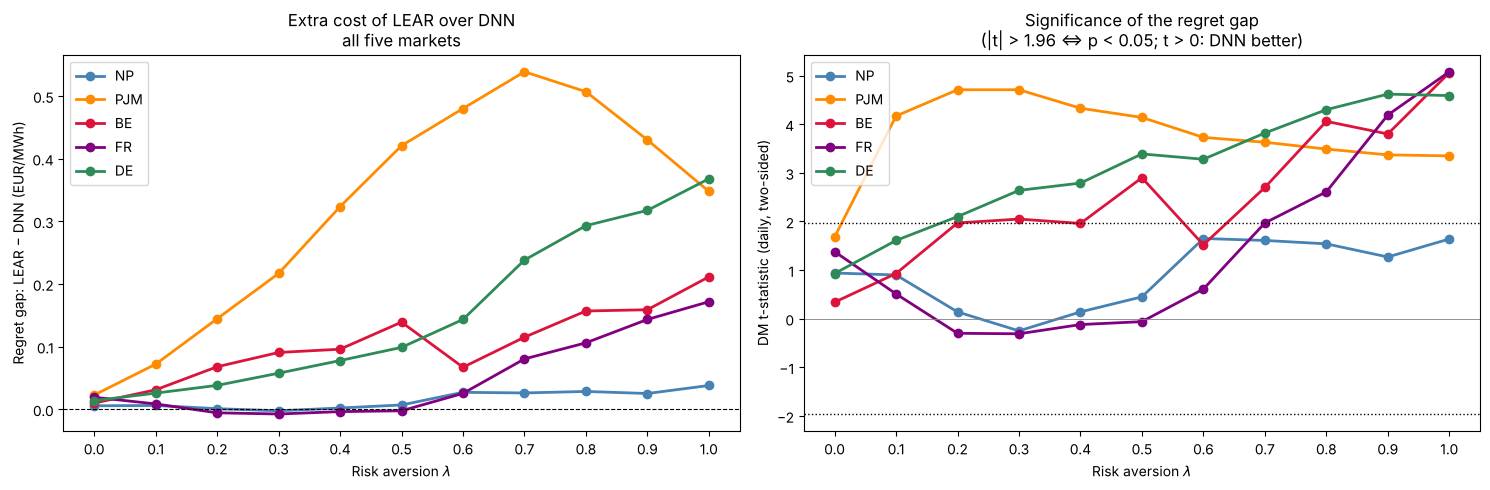

Figure saved → figures/cross_market_regret_dm.png


In [25]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
colors = {"NP": "steelblue", "PJM": "darkorange", "BE": "crimson",
          "FR": "purple",    "DE":  "seagreen"}

# --- Left: regret gap (LEAR - DNN) vs lambda for all markets ---
ax = axes[0]
for market, dm_df in all_dm.items():
    ax.plot(dm_df.index, dm_df["Gap"], marker="o", linewidth=2,
            color=colors[market], label=market)
ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_xlabel("Risk aversion $\\lambda$")
ax.set_ylabel("Regret gap: LEAR − DNN (EUR/MWh)")
ax.set_title("Extra cost of LEAR over DNN\nall five markets")
ax.legend()
ax.set_xticks(LAMBDAS)

# --- Right: DM t-statistic vs lambda for all markets ---
ax = axes[1]
for market, dm_df in all_dm.items():
    ax.plot(dm_df.index, dm_df["t"], marker="o", linewidth=2,
            color=colors[market], label=market)
for y in (1.96, -1.96):
    ax.axhline(y, color="black", linewidth=1, linestyle=":")
ax.axhline(0, color="grey", linewidth=0.6)
ax.set_xlabel("Risk aversion $\\lambda$")
ax.set_ylabel("DM t-statistic (daily, two-sided)")
ax.set_title("Significance of the regret gap\n(|t| > 1.96 ⇔ p < 0.05; t > 0: DNN better)")
ax.legend()
ax.set_xticks(LAMBDAS)

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/cross_market_regret_dm.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figure saved → figures/cross_market_regret_dm.png")

## Cross-market interpretation

1. **Is there a significant regret difference everywhere?** No. The DNN has significantly lower regret from λ = 0.1 in PJM, 0.2 in BE and DE, and 0.7 in FR; never at 5 % in NP. LEAR is never significantly better.
2. **Is it larger where tails are heavier?** Not in a simple way. At λ = 1 the gap is largest in DE (+0.37) and PJM (+0.35), then BE (+0.21) and FR (+0.17), and smallest in NP (+0.04), while FR and BE have by far the heaviest tails.
3. **Does it grow monotonically with λ?** Not everywhere: FR is slightly negative between λ = 0.2 and 0.5, PJM peaks at λ = 0.7, BE dips at λ = 0.6 (and is borderline, p ≈ 0.05, between λ = 0.2 and 0.4).
4. **At λ = 0** no market shows a significant regret difference.

The onset, size and shape of the regret gap are market-specific.

---

# Mechanism checks — tail bias and calibration

Two checks on all five markets:

1. **Signed error in the top decile**, with hours grouped by the **forecast** (what the buyer sees when deciding) and, for comparison, by the **realised** price.
2. **Calibration of the 80 % interval** — overall, and in the hours with the highest forecasts.

Grouping by realised price selects the hours with the largest positive shocks: even a perfect forecast of the conditional mean would look biased downward there, and its intervals would look too narrow. Grouping by forecast avoids this selection effect.

In [26]:
from decision_utils import MARKET_FILES, tail_calibration

# ── Check 1: signed error in the top decile — grouped by FORECAST and by REALISED price ──
# Grouping hours by realised price selects the hours with the largest positive shocks, so even a
# perfect forecast of the conditional mean looks biased downward there (selection effect).
# Grouping by forecast decile uses only what the buyer sees when deciding.
rows = []
for market, path in MARKET_FILES.items():
    df = pd.read_csv(path, index_col=0, parse_dates=True)
    for model in ["DNN Ensemble", "LEAR Ensemble"]:
        c = tail_calibration(df, model)
        rows.append({"Market": market, "Model": model.split()[0],
                     "Bias, top forecast decile": c["bias_top_forecast"],
                     "Bias, top realised-price decile": c["bias_top_realised"]})

bias_df = pd.DataFrame(rows).set_index(["Market", "Model"])
print("Mean signed error (forecast − actual) in the top decile, evaluation hours [EUR/MWh]\n")
print(bias_df.round(2).to_string())

Mean signed error (forecast − actual) in the top decile, evaluation hours [EUR/MWh]

              Bias, top forecast decile  Bias, top realised-price decile
Market Model                                                            
NP     DNN                        -0.98                            -2.72
       LEAR                       -0.56                            -2.49
PJM    DNN                         0.86                            -2.99
       LEAR                       -2.27                            -6.43
BE     DNN                        -8.43                           -18.78
       LEAR                       -6.75                           -18.27
FR     DNN                        -4.10                            -6.85
       LEAR                       -2.67                            -5.32
DE     DNN                        -1.64                            -4.16
       LEAR                       -3.38                            -5.84


In [27]:
# ── Check 2: calibration of the 80 % interval — overall and in the top decile ──
# Interval = forecast + 10th / 90th percentile of the past 90 days of residuals (eq. 3.5).
# Expected: 80 % coverage; the price exceeds the predicted 90th percentile in 10 % of hours.
rows = []
for market, path in MARKET_FILES.items():
    df = pd.read_csv(path, index_col=0, parse_dates=True)
    for model in ["DNN Ensemble", "LEAR Ensemble"]:
        c = tail_calibration(df, model)
        rows.append({"Market": market, "Model": model.split()[0],
                     "Cov. 80%, all hours":              c["cov80_all"],
                     "Cov. 80%, top forecast decile":    c["cov80_top_forecast"],
                     "P(p > q90), all hours":            c["exceed_q90_all"],
                     "P(p > q90), top forecast decile":  c["exceed_q90_top_forecast"],
                     "Cov. 80%, top realised decile*":   c["cov80_top_realised"]})

calib_df = pd.DataFrame(rows).set_index(["Market", "Model"])
print("Calibration of the rolling-residual predictive distribution [% of evaluation hours]\n")
print((100 * calib_df).round(1).to_string())
print("\n* selection-biased: hours chosen because the price ended high; shown for comparison only")

Calibration of the rolling-residual predictive distribution [% of evaluation hours]

              Cov. 80%, all hours  Cov. 80%, top forecast decile  P(p > q90), all hours  P(p > q90), top forecast decile  Cov. 80%, top realised decile*
Market Model                                                                                                                                            
NP     DNN                   77.5                           67.6                   11.3                             16.6                            65.2
       LEAR                  78.1                           67.4                   10.6                             13.8                            65.6
PJM    DNN                   78.5                           50.9                   10.6                             22.6                            42.0
       LEAR                  77.9                           56.0                   11.0                             26.6                            46

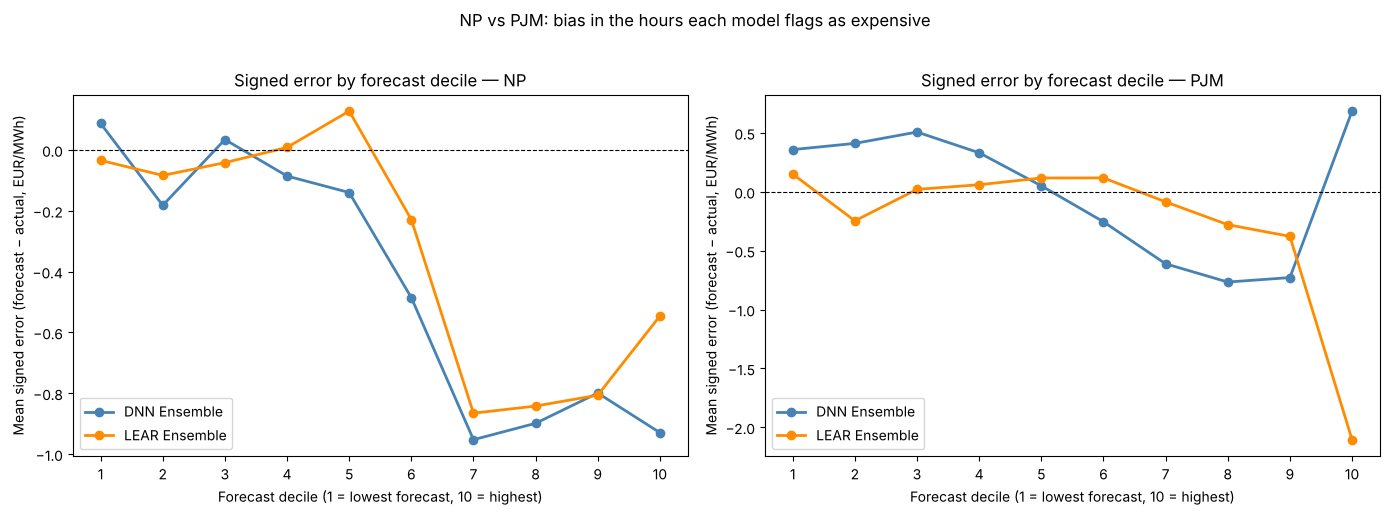

Figure saved → figures/bias_by_forecast_decile_NP_PJM.png


In [28]:
# ── Visual: signed error by FORECAST decile for NP and PJM ────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, market in zip(axes, ["NP", "PJM"]):
    df = pd.read_csv(MARKET_FILES[market], index_col=0, parse_dates=True)
    x = list(range(1, 11))
    for model, color in [("DNN Ensemble", "steelblue"), ("LEAR Ensemble", "darkorange")]:
        dec  = pd.qcut(df[model], 10, labels=False) + 1        # decile of the FORECAST
        bias = [(df[model] - df["Real price"])[dec == d].mean() for d in x]
        ax.plot(x, bias, marker="o", color=color, label=model, linewidth=2)
    ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
    ax.set_xlabel("Forecast decile (1 = lowest forecast, 10 = highest)")
    ax.set_ylabel("Mean signed error (forecast − actual, EUR/MWh)")
    ax.set_title(f"Signed error by forecast decile — {market}")
    ax.set_xticks(x)
    ax.legend()

plt.suptitle("NP vs PJM: bias in the hours each model flags as expensive", fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/bias_by_forecast_decile_NP_PJM.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figure saved → figures/bias_by_forecast_decile_NP_PJM.png")

## Forward-premium sensitivity — NP and PJM

The forward proxy `f = rolling_mean × (1 + π)` uses an assumed premium. We recompute the regret gap at π = 0 %, 5 % and 10 % for NP and PJM to check that the direction of the gap does not depend on that choice.


--- NP ---
  π=0%  computing DNN... 

LEAR... 

done
    Gap at λ=1: +0.0578  → DNN wins
  π=5%  computing DNN... 

LEAR... 

done
    Gap at λ=1: +0.0380  → DNN wins
  π=10%  computing DNN... 

...

done
    Gap at λ=1: +0.2038  → DNN wins
  π=5%  computing DNN... 

LEAR... 

done
    Gap at λ=1: +0.3478  → DNN wins
  π=10%  computing DNN... 

LEAR... 

done
    Gap at λ=1: +0.5165  → DNN wins


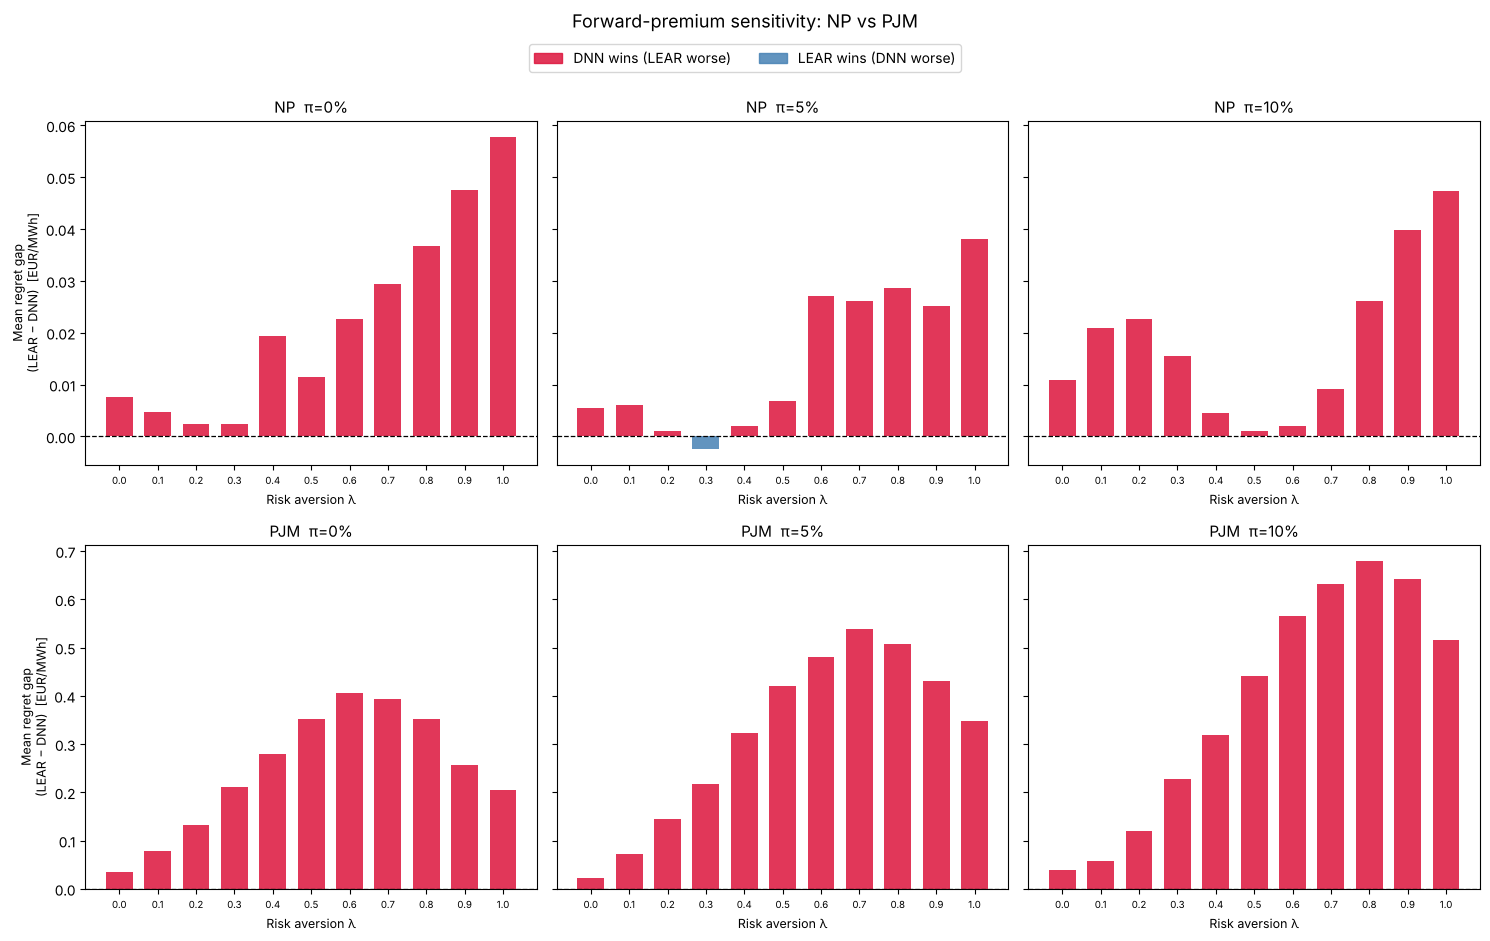


Saved → figures/premium_sensitivity_NP_PJM.png


In [29]:
# ── Forward-premium sensitivity: NP and PJM ──────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

WINDOW  = 90 * 24
ALPHA   = 0.10
LAMBDAS = np.round(np.arange(0, 1.1, 0.1), 1)
premiums = [0.00, 0.05, 0.10]

sens_markets = {
    'NP':  f'{DATA_DIR}/Forecasts_NP_DNN_LEAR_ensembles.csv',
    'PJM': f'{DATA_DIR}/Forecasts_PJM_DNN_LEAR_ensembles.csv',
}

fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharey='row')

for row, (market, path) in enumerate(sens_markets.items()):
    df = pd.read_csv(path, index_col=0, parse_dates=True)
    print(f'\n--- {market} ---')

    for col_idx, pi in enumerate(premiums):
        ax = axes[row, col_idx]
        f_pi = df['Real price'].shift(1).rolling(WINDOW).mean() * (1 + pi)

        print(f'  π={int(pi*100)}%  computing DNN...', end=' ', flush=True)
        reg_dnn  = compute_regret(df, 'DNN Ensemble',  f_pi, WINDOW, ALPHA, LAMBDAS)
        print('LEAR...', end=' ', flush=True)
        reg_lear = compute_regret(df, 'LEAR Ensemble', f_pi, WINDOW, ALPHA, LAMBDAS)
        print('done')

        mean_dnn  = reg_dnn.mean()
        mean_lear = reg_lear.mean()
        gap       = mean_lear - mean_dnn   # positive → LEAR worse → DNN wins
        lam_vals  = [float(c.split('=')[1]) for c in mean_dnn.index]

        # bar: red = DNN wins, blue = LEAR wins
        colors = ['crimson' if g > 0 else 'steelblue' for g in gap.values]
        ax.bar(lam_vals, gap.values, width=0.07, color=colors, alpha=0.85)
        ax.axhline(0, color='black', linewidth=0.9, linestyle='--')
        ax.set_title(f'{market}  π={int(pi*100)}%', fontsize=11)
        ax.set_xlabel('Risk aversion λ', fontsize=9)
        ax.set_xticks(lam_vals)
        ax.set_xticklabels([f'{l:.1f}' for l in lam_vals], fontsize=7)
        if col_idx == 0:
            ax.set_ylabel('Mean regret gap\n(LEAR − DNN)  [EUR/MWh]', fontsize=9)

        # print gap at λ=1 for easy reading
        gap_at_1 = gap.iloc[-1]
        winner = 'DNN' if gap_at_1 > 0 else 'LEAR'
        print(f'    Gap at λ=1: {gap_at_1:+.4f}  → {winner} wins')

from matplotlib.patches import Patch
legend_handles = [
    Patch(color='crimson',   alpha=0.85, label='DNN wins (LEAR worse)'),
    Patch(color='steelblue', alpha=0.85, label='LEAR wins (DNN worse)'),
]
fig.legend(handles=legend_handles, loc='upper center', ncol=2,
           fontsize=10, bbox_to_anchor=(0.5, 1.01))
fig.suptitle('Forward-premium sensitivity: NP vs PJM',
             y=1.04, fontsize=13)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/premium_sensitivity_NP_PJM.png', dpi=150, bbox_inches='tight')
plt.show()
print('\nSaved → figures/premium_sensitivity_NP_PJM.png')

## Who hedges correctly? — Disagreement breakdown

Both models agree most of the time. The interesting hours are when they **disagree**:
- **Case A:** DNN hedges (z*=1), LEAR doesn't (z*=0)
- **Case B:** LEAR hedges (z*=1), DNN doesn't (z*=0)

For each case we ask: what did the oracle say?
- If oracle says *don't hedge* → the model that didn't hedge was right
- If oracle says *hedge* → the model that hedged was right

The **volume** of each case (not just accuracy) is what drives the regret gap.

NP  λ=1.0, π=5%
  Case A (only DNN hedges):  268 hrs — LEAR right 267 (99.6%), DNN right 1
  Case B (only LEAR hedges): 401 hrs — DNN right 398 (99.3%), LEAR right 3


PJM  λ=1.0, π=5%
  Case A (only DNN hedges):  281 hrs — LEAR right 274 (97.5%), DNN right 7
  Case B (only LEAR hedges): 634 hrs — DNN right 632 (99.7%), LEAR right 2


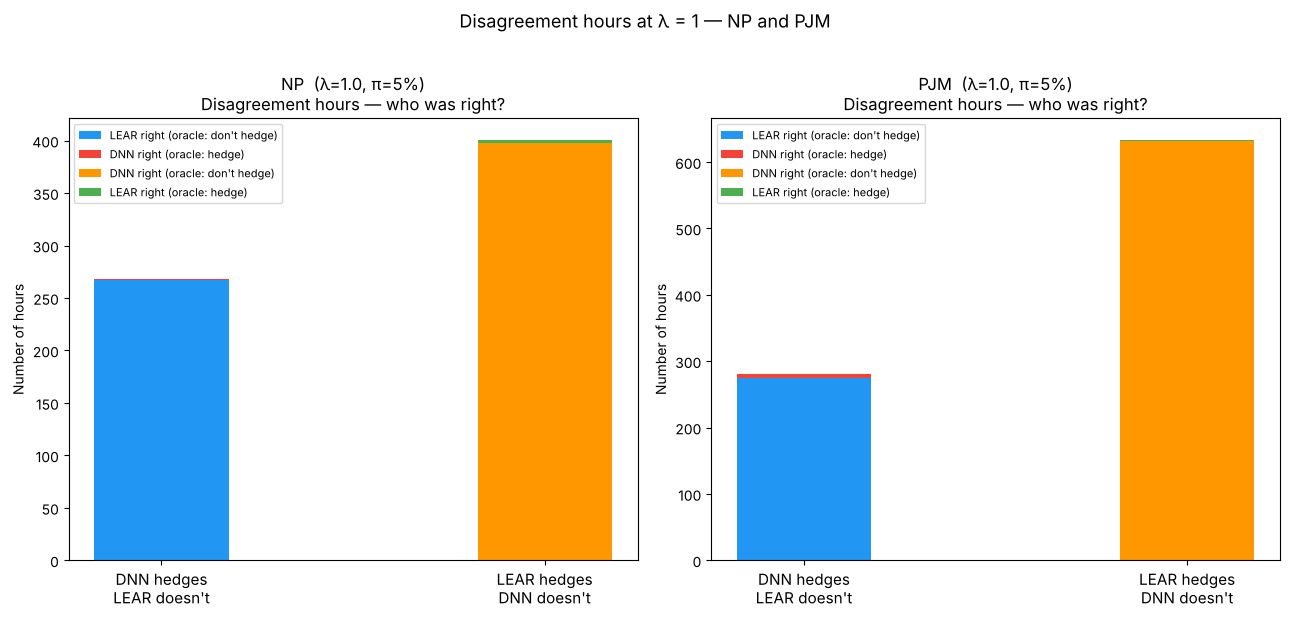

Saved → figures/disagreement_NP_PJM.png


In [30]:
from decision_utils import forward_proxy, decisions, PREMIUM

LAM = 1.0
fig, axes = plt.subplots(1, 2, figsize=(13, 6))

for ax, market in zip(axes, ["NP", "PJM"]):
    df   = pd.read_csv(MARKET_FILES[market], index_col=0, parse_dates=True)
    f_pi = forward_proxy(df["Real price"], WINDOW, PREMIUM)    # π = 5 %, as in the regret tables

    dnn    = decisions(df, "DNN Ensemble",  f_pi, LAM)
    lear   = decisions(df, "LEAR Ensemble", f_pi, LAM)
    oracle = dnn["z_oracle"]

    # Case A: DNN hedges, LEAR doesn't
    caseA        = (dnn["z_star"] == 1) & (lear["z_star"] == 0)
    A_lear_right = ((oracle == 0) & caseA).sum()
    A_dnn_right  = ((oracle == 1) & caseA).sum()

    # Case B: LEAR hedges, DNN doesn't
    caseB        = (dnn["z_star"] == 0) & (lear["z_star"] == 1)
    B_dnn_right  = ((oracle == 0) & caseB).sum()
    B_lear_right = ((oracle == 1) & caseB).sum()

    print(f"{market}  λ={LAM}, π=5%")
    print(f"  Case A (only DNN hedges):  {caseA.sum()} hrs — LEAR right {A_lear_right} "
          f"({100*A_lear_right/max(caseA.sum(),1):.1f}%), DNN right {A_dnn_right}")
    print(f"  Case B (only LEAR hedges): {caseB.sum()} hrs — DNN right {B_dnn_right} "
          f"({100*B_dnn_right/max(caseB.sum(),1):.1f}%), LEAR right {B_lear_right}")

    ax.bar(0, A_lear_right, 0.35, color="#2196F3", label="LEAR right (oracle: don't hedge)")
    ax.bar(0, A_dnn_right,  0.35, bottom=A_lear_right, color="#F44336", label="DNN right (oracle: hedge)")
    ax.bar(1, B_dnn_right,  0.35, color="#FF9800", label="DNN right (oracle: don't hedge)")
    ax.bar(1, B_lear_right, 0.35, bottom=B_dnn_right, color="#4CAF50", label="LEAR right (oracle: hedge)")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["DNN hedges\nLEAR doesn't", "LEAR hedges\nDNN doesn't"], fontsize=11)
    ax.set_ylabel("Number of hours", fontsize=10)
    ax.set_title(f"{market}  (λ=1.0, π=5%)\nDisagreement hours — who was right?", fontsize=12)
    ax.legend(fontsize=8, loc="upper left")

plt.suptitle("Disagreement hours at λ = 1 — NP and PJM", fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/disagreement_NP_PJM.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → figures/disagreement_NP_PJM.png")

## Interpretation — mechanism checks

**Tail bias.** Grouped by forecast decile, the top-decile bias is small in NP (−1.0 and −0.6 EUR/MWh for DNN and LEAR) and largest in BE (−8.4 and −6.8); in PJM the DNN is slightly positive (+0.9). Grouped by realised price, the same markets look much more biased (−2.5 to −18.8): most of that is the selection effect.

**Calibration.** Over all hours the 80 % interval covers 77.5 to 78.9 % (nominal 80 %), and the price exceeds the predicted 90th percentile in 10.6 to 11.4 % of hours (nominal 10 %): close to calibrated. In the hours with the highest forecasts, the price exceeds the predicted 90th percentile in 13.8 to 26.8 % of cases: tail risk is under-estimated when a high price is forecast.

**Who wins and why.** Which model is less biased in the tail varies by market (LEAR in NP, BE and FR; the DNN in PJM and DE), yet the DNN has the lower regret at λ = 1 in all five markets. In the disagreement hours, the oracle sides with the model that does not hedge in 97 to 100 % of cases (NP: 268 hours where only the DNN hedges vs 401 where only LEAR hedges; PJM: 281 vs 634). The model with lower regret is the one that triggers fewer unnecessary hedges.

**Premium sensitivity.** The gap at λ = 1 keeps its sign at π = 0 %, 5 % and 10 % in NP (+0.058, +0.038, +0.047) and PJM (+0.204, +0.348, +0.517).

> **Correction (14 Oct 2026).** Earlier versions of these cells described a "PJM reversal" in which LEAR won at high λ. With the predictive distribution of eq. 3.5 there is no reversal: the DNN has significantly lower regret in PJM at every λ ≥ 0.1.

---

# Final Synthesis — The Answer to the Research Question

> *As risk aversion λ increases, does the ranking of forecasting models by decision value diverge from their ranking by statistical accuracy?*

**Step 1 — Fat tails (Phase 1).** Prices are right-skewed with heavy tails: extreme in FR and BE (excess kurtosis 522 and 147), mild in NP (3.8).

**Step 2 — Error by price decile (Phase 2).** Grouped by realised price, both models look strongly biased downward in the top decile, but this is largely a selection effect. Grouped by forecast decile, the top-decile bias ranges from −8.4 to +0.9 EUR/MWh depending on market and model.

**Step 3 — Calibration (Phase 3).** The rolling-residual predictive distribution is close to calibrated overall (80 % interval: 77.5–78.9 % coverage) but under-states tail risk when a high price is forecast (price above the predicted 90th percentile in 13.8–26.8 % of those hours instead of 10 %).

**Step 4 — Regret (Phase 4).** Regret rises with λ for both models. At λ = 1 the DNN has the lower regret in all five markets; the gap ranges from 0.04 EUR/MWh (NP) to 0.37 (DE).

**Step 5 — Significance (Phase 5).** At λ = 0 no market shows a significant regret difference. The DNN becomes significantly better from λ = 0.1 (PJM), 0.2 (BE, DE) or 0.7 (FR), and never at 5 % in NP. By MAE the DNN is significantly better in four markets (not FR).

**Answer.** At λ = 0, accuracy and decision value agree. As λ grows, what decision evaluation adds to accuracy depends on the market: the onset, size and shape of the regret gap are market-specific, and in NP a small accuracy advantage never becomes a detectable decision advantage. The 10-model rank correlation in `cross_market_decision.ipynb` (Phase 7) shows the same market dependence.

*Exploratory notebook on the Lago et al. (2021) benchmark forecast files. Reference results: `cross_market_decision.ipynb`.*